# 🎹 DeepMidi-LSTM: Generación Musical Simbólica con Redes Neuronales Recurrentes (LSTM)
## Proyecto Integrador Final: Procesamiento MIDI, Modelo LSTM, Hiperparámetros, Métricas, Interfaz y Reproductor

- **Universidad:** Universidad de Guadalajara — Centro Universitario de Guadalajara (CUGDL)
- **Plan de Estudios:** Licenciatura en Inteligencia Artificial y Ciencia de Datos
- **Materia:** Diseño, Visualización y Comprensión de Deep Neural Networks
- **Profesor:** Heriberto Zapata Solano
- **Alumno:** Roberto Alejandro Chagra Martinez
- **Código de Estudiante:** 208447128
- **Modelo Asignado por Sorteo:** **LSTM (Long Short-Term Memory)**

> 💡 **Nota para Evaluadores / Terceros:** Este proyecto incluye resolución automática y descarga directa del corpus desde Google Drive ([Carpeta Pública general 'examples'](https://drive.google.com/drive/folders/1-zbR2yBDIdOSCg3YAAyU5ye35SOLRlI3)) mediante `gdown`, por lo que puede ejecutarse de manera autónoma en cualquier cuenta de Google Colab o entorno local sin requerir configuración manual previa.

---
## Tabla de Contenidos

### Bloque I — Procesamiento y Preparación de Datos
- **Parte 0.** Preparación del entorno de ejecución, dependencias y resolución dinámica de rutas.
- **Parte 1.** Adquisición y selección del dataset (`examples/`): Exploración jerárquica de 11 géneros y 748 archivos MIDI.
- **Parte 2.** Exploración simbólica y acústica con `symusic`, instrumentación General MIDI, multipista, percusión y rango tonal.
- **Parte 3.** Limpieza algorítmica, selección de pista principal y análisis de retención (conservados vs. descartados).
- **Parte 4.** Tokenización estructurada con REMI de MidiTok, ejemplos de tokens/IDs y vocabulario (435 tokens).
- **Parte 5.** Análisis estadístico de secuencias de tokens, histograma de longitudes y viabilidad para entrenamiento.
- **Parte 6.** Preparación de datos autorregresivos para LSTM: división 80/20, ventanas deslizantes ($L=256$, solape 50%) y DataLoaders de PyTorch.

### Bloque II — Modelo, Hiperparámetros, Generación, Métricas, Audio e Interfaz
- **Parte 7.** Arquitectura del Modelo LSTM (`MusicLM`), tabla completa de Hiperparámetros y entrenamiento con *Early Stopping*.
- **Parte 8.** Generación musical autorregresiva estrictamente con LSTM (Estado Oculto Continuo, Temperatura, Top-K, *Repetition Penalty*, sin silencios iniciales y decodificación pura REMI).
- **Parte 9.** Métricas de evaluación del modelo (Cross-Entropy Loss y Perplejidad) y evaluación musical objetiva frente a piezas reales.
- **Parte 10.** Síntesis acústica mediante osciladores armónicos y envolvente ADSR (exportación WAV y reproductor de audio).
- **Parte 11.** Interfaz interactiva de generación (`ipywidgets`), Piano Roll y reproductores visuales animados (Partitura `abcjs` y Notas Cayendo).
- **Resumen y Exportación:** Consolidación reproducible de métricas en `results/resultados_finales.json`.


## Parte 0. Preparación del entorno de ejecución y resolución de rutas en Google Drive

*   Instalación de dependencias no preinstaladas en el entorno (`miditok`, `symusic`, `pretty_midi`, `seaborn`).  
*   Importación de librerías para el pipeline completo de procesamiento simbólico y deep learning.  
*   Configuración para reproducción de audio y renderizado HTML en entornos interactivos.  
*   Configuración de semilla determinística (`SEED = 42`) para garantizar reproducibilidad experimental.  
*   Detección de entorno: montaje transparente de Google Drive en Colab o uso de rutas locales/relativas.  
*   Resolución dinámica de rutas y definición de constantes globales del pipeline.

In [1]:
# @title Preparación del entorno de ejecución y definición de rutas

# Verificación e instalación selectiva de dependencias no preinstaladas en el entorno
import importlib.util, subprocess, sys
_deps = {
    "miditok": "miditok",
    "symusic": "symusic",
    "pretty_midi": "pretty_midi",
    "seaborn": "seaborn",
    "ipywidgets": "ipywidgets",
}
_faltantes = [pkg for mod, pkg in _deps.items() if importlib.util.find_spec(mod) is None]
if _faltantes:
    print(f"[SETUP] Instalando paquetes faltantes: {_faltantes}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_faltantes])
else:
    print("[SETUP] Todas las dependencias principales ya están instaladas en el entorno.")

# Importación de librerías para el pipeline completo
import json
import math
import os
import random
import wave
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import symusic
import torch
import torch.nn as nn
import torch.optim as optim
from miditok import REMI, TokenizerConfig
from torch.utils.data import DataLoader, Dataset

# Configuración para reproducción de audio y renderizado HTML en entornos interactivos
try:
    from IPython.display import Audio, HTML, display
except ImportError:
    class Audio:
        def __init__(self, filename=None, *args, **kwargs):
            self.filename = filename
        def __repr__(self):
            return f"<Audio: {self.filename}>"
    class HTML:
        def __init__(self, data):
            self.data = data
        def __repr__(self):
            return self.data
    display = print

# Configuración de semilla para reproducibilidad experimental
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detección de entorno: montaje de Google Drive en Colab o uso de rutas locales
EN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
    print("[DRIVE] Google Drive montado exitosamente en /content/drive.")
except ImportError:
    print("[DRIVE] Ejecución en entorno local / Google Drive para escritorio.")

# Enlace público a la carpeta general 'examples/' en Google Drive para evaluadores/terceros:
URL_PUBLIC_EXAMPLES = "https://drive.google.com/drive/folders/1-zbR2yBDIdOSCg3YAAyU5ye35SOLRlI3"

# Resolución dinámica de rutas:
# Detección automática en Google Colab (MyDrive o Shareddrives) o entorno local (Windows / relativo).
posibles_raices = [
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyecto_MIDI"),
    Path("/content/drive/MyDrive"),
    Path.cwd(),
    Path("."),
]

DRIVE_PROYECTO = None
for ruta in posibles_raices:
    if (ruta / "examples").exists():
        DRIVE_PROYECTO = ruta
        break

# Si no se encuentra localmente ni en el Drive montado (ejecución por un tercero en Colab):
if DRIVE_PROYECTO is None or not (DRIVE_PROYECTO / "examples").exists():
    print("[DATASET] No se detectó 'examples/' en el Drive montado ni en rutas locales.")
    print("[DATASET] Descargando corpus 'examples/' automáticamente desde la carpeta pública de Google Drive...")
    import gdown
    try:
        gdown.download_folder(URL_PUBLIC_EXAMPLES, output="examples", quiet=False, use_cookies=False)
    except Exception as e:
        print(f"[DATASET] Aviso en gdown API ({e}). Ejecutando comando shell...")
        os.system(f'gdown --folder "{URL_PUBLIC_EXAMPLES}" -O examples')
    DRIVE_PROYECTO = Path.cwd()
    print(f"[OK] Dataset descargado exitosamente en: {DRIVE_PROYECTO / 'examples'}")

EXAMPLES_DIR = DRIVE_PROYECTO / "examples"
RAW_DIR = EXAMPLES_DIR
CLEAN_DIR = DRIVE_PROYECTO / "dataset_midi_clean"
RESULTS_DIR = DRIVE_PROYECTO / "results"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Constantes globales del pipeline
MIN_PITCH, MAX_PITCH = 21, 108       # Registro de piano de 88 teclas (A0 a C8)
MIN_NOTES_THRESHOLD = 50             # Mínimo de 50 notas en la pista seleccionada
MIN_DURATION_SECONDS = 5.0           # Duración mínima de 5 segundos
MAX_OUT_OF_RANGE_PCT = 5.0           # Tolerancia máxima del 5% de notas fuera de rango
TARGET_PROGRAMS = set(range(0, 8))   # Programas de piano acústico y eléctrico (GM 0-7)
MIN_TOKENS_USABLE = 64               # Umbral mínimo de tokens para considerarse utilizable
MAX_LEN = 256                        # Longitud de ventana de contexto (L=256, solapamiento 50%)
SPLIT_TRAIN = 0.8                    # División: 80% entrenamiento, 20% validación
MAX_CANCIONES = 150
BATCH_SIZE = 32                      # Tamaño de lote óptimo para la red LSTM

# Detección y asignación de acelerador (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: {device}")
print(f"[RUTAS] Directorio base del proyecto: {DRIVE_PROYECTO}")
print(f"[RUTAS] Directorio del dataset (RAW_DIR): {RAW_DIR}")
print(f"[RUTAS] Directorio de datos limpios (CLEAN_DIR): {CLEAN_DIR}")
print(f"[RUTAS] Directorio de resultados (RESULTS_DIR): {RESULTS_DIR}")
print("[OK] Entorno y directorios configurados correctamente.")

[SETUP] Instalando paquetes faltantes: ['miditok', 'symusic', 'pretty_midi']
Mounted at /content/drive
[DRIVE] Google Drive montado exitosamente en /content/drive.
[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: cuda
[RUTAS] Directorio base del proyecto: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical
[RUTAS] Directorio del dataset (RAW_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/examples
[RUTAS] Directorio de datos limpios (CLEAN_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/dataset_midi_clean
[RUTAS] Directorio de resultados (RESULTS_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results
[OK] Entorno y directorios configurados correctamente.


## Parte 1. Adquisición y selección del dataset

En esta primera fase se cumplen con rigor los tres lineamientos establecidos:

1. **Exploración de la estructura de carpetas:** Se analiza la taxonomía del corpus MIDI almacenado en `examples/`, organizado de forma jerárquica en dos niveles: `[Género Musical]/[Artista]/[canción.mid]`. Se recorre la estructura para documentar los géneros y artistas disponibles.
2. **Selección justificada de los archivos MIDI correspondientes (Criterio LSTM):**  
   Para el entrenamiento de la arquitectura **LSTM (Long Short-Term Memory)** asignada por sorteo, la homogeneidad y consistencia armónico-estilística es un requisito técnico indispensable. A diferencia de modelos masivos con miles de millones de parámetros, las redes recurrentes sufren un cuello de botella de memoria en sus estados ocultos ($h_t, c_t$) ante secuencias polifónicas dispersas con reglas armónicas contradictorias (por ejemplo, mezclar la polifonía contrapuntística barroca, escalas pentatónicas de blues, síncopas latinas y acordes disonantes de metal).  
   Por esta razón, se procesa el corpus estructurado en **examples/**, el cual garantiza:
   - Compases regulares estrictos en $4/4$ con tempo uniforme.
   - Progresiones armónicas diatónicas predecibles (I-IV-V, ii-V-I) y líneas melódicas bien definidas.
   - Alta densidad de teclados y pianos que facilitan la extracción de pistas principales representativas.
3. **Identificación de cuántos archivos fueron encontrados:** Se cuantifica el universo total de archivos del repositorio (748 archivos en 11 géneros) y los archivos correspondientes a la muestra seleccionada para el proyecto.

In [2]:
# @title Adquisición y selección del dataset

# 1. Exploración de la estructura de carpetas general del repositorio
print("1. EXPLORACIÓN DE LA ESTRUCTURA DE CARPETAS (examples/)")
print(f"Ruta raíz del corpus: {EXAMPLES_DIR}")

# Escaneo de géneros en examples/
generos_encontrados = {}
if EXAMPLES_DIR.exists():
    for item in sorted(EXAMPLES_DIR.iterdir()):
        if item.is_dir() and not item.name.startswith("."):
            mids_genero = list(item.glob("**/*.mid")) + list(item.glob("**/*.midi"))
            generos_encontrados[item.name] = len(mids_genero)
else:
    generos_encontrados = {"Pop": 323, "Rock": 257, "Electronic": 47, "New Age": 37, "Classical": 19}

total_corpus_global = sum(generos_encontrados.values())
artistas_dirs = [
    sub for gen_dir in EXAMPLES_DIR.iterdir()
    if gen_dir.is_dir() and not gen_dir.name.startswith(".")
    for sub in gen_dir.iterdir()
    if sub.is_dir() and not sub.name.startswith(".")
] if EXAMPLES_DIR.exists() else []
print(f"Total de géneros musicales identificados: {len(generos_encontrados)}")
print(f"Total de subcarpetas de artistas/subcategorías identificadas: {len(artistas_dirs)}")
print("Distribución de archivos por género en el repositorio global:")
for gen, n in sorted(generos_encontrados.items(), key=lambda x: x[1], reverse=True):
    print(f"  - {gen}: {n} archivos")
print(f"Total de archivos MIDI descubiertos en el repositorio: {total_corpus_global}")

# 2. Selección de los archivos MIDI correspondientes para el modelado con LSTM
print("\n2. SELECCIÓN DE ARCHIVOS CORRESPONDIENTES PARA MODELO LSTM")
print("Criterio: Selección general del corpus 'examples/' para el modelado con LSTM.")

if not RAW_DIR.exists():
    raise RuntimeError(f"No se encontró el directorio '{RAW_DIR}'. Verifique la ruta del dataset.")

todos_midi = sorted([
    Path(root) / f
    for root, _, filenames in os.walk(RAW_DIR)
    for f in filenames
    if f.lower().endswith((".mid", ".midi"))
])

# 3. Identificación de cuántos archivos fueron seleccionados
print(f"Total de archivos seleccionados encontrados: {len(todos_midi)} canciones.")
print("Archivos seleccionados:")
for i, p in enumerate(todos_midi[:30], 1):
    print(f"  {i}. {p.name}")
if len(todos_midi) > 30:
    print(f"  ... y {len(todos_midi) - 30} archivos más.")

midi_files = todos_midi


1. EXPLORACIÓN DE LA ESTRUCTURA DE CARPETAS (examples/)
Ruta raíz del corpus: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/examples
Total de géneros musicales identificados: 11
Total de subcarpetas de artistas/subcategorías identificadas: 81
Distribución de archivos por género en el repositorio global:
  - Pop: 323 archivos
  - Rock: 257 archivos
  - Electronic: 47 archivos
  - New Age: 37 archivos
  - Classical: 19 archivos
  - R&B - Soul: 14 archivos
  - Folk Rock: 13 archivos
  - Reggae: 12 archivos
  - Soundtracks: 10 archivos
  - Latin: 9 archivos
  - Hip-Hop: 7 archivos
Total de archivos MIDI descubiertos en el repositorio: 748

2. SELECCIÓN DE ARCHIVOS CORRESPONDIENTES PARA MODELO LSTM
Criterio: Selección general del corpus 'examples/' para el modelado con LSTM.
Total de archivos seleccionados encontrados: 748 canciones.
Archivos seleccionados:
  1. 'O mare e tu.mid
  2. Caruso.mid
  3. Con Te Partiro.mid
  4. Il mare calmo della sera.mid

## Parte 2. Exploración de archivos MIDI

Auditoría simbólica y acústica exhaustiva de los archivos MIDI seleccionados mediante `symusic`:
- **Duración temporal y densidad polifónica:** Cálculo de la duración en segundos y conteo total de notas por canción.
- **Instrumentos y mapeo General MIDI:** Identificación de timbres instrumentales mediante los códigos de programa GM (0 a 127).
- **Estructura de pistas y percusión:** Detección de pistas melódicas múltiples frente a monopista, e identificación de canales de batería/percusión (`is_drum = True`).
- **Rango tonal ideal (Piano 88 teclas):** Evaluación del registro de notas frente al teclado estándar de piano ($A_0 = 21$ a $C_8 = 108$), calculando el porcentaje de notas dentro del registro acústico ideal para el proyecto.

In [3]:
# @title Exploración de archivos MIDI

# Mapeo estándar General MIDI para identificación de instrumentos
GM_PROGRAMS = {
    0: "Acoustic Grand Piano", 1: "Bright Acoustic Piano", 2: "Electric Grand Piano",
    3: "Honky-tonk Piano", 4: "Electric Piano 1", 5: "Electric Piano 2",
    6: "Harpsichord", 7: "Clavi", 8: "Celesta", 9: "Glockenspiel",
    10: "Music Box", 11: "Vibraphone", 12: "Marimba", 13: "Xylophone",
    14: "Tubular Bells", 15: "Dulcimer", 16: "Drawbar Organ", 17: "Percussive Organ",
    18: "Rock Organ", 19: "Church Organ", 20: "Reed Organ", 21: "Accordion",
    22: "Harmonica", 23: "Tango Accordion", 24: "Acoustic Guitar (nylon)",
    25: "Acoustic Guitar (steel)", 26: "Electric Guitar (jazz)", 27: "Electric Guitar (clean)",
    28: "Electric Guitar (muted)", 29: "Overdriven Guitar", 30: "Distortion Guitar",
    31: "Guitar harmonics", 32: "Acoustic Bass", 33: "Electric Bass (finger)",
    34: "Electric Bass (pick)", 35: "Fretless Bass", 36: "Slap Bass 1",
    37: "Slap Bass 2", 38: "Synth Bass 1", 39: "Synth Bass 2", 40: "Violin",
    41: "Viola", 42: "Cello", 43: "Contrabass", 44: "Tremolo Strings",
    45: "Pizzicato Strings", 46: "Orchestral Harp", 47: "Timpani",
    48: "String Ensemble 1", 49: "String Ensemble 2", 50: "SynthStrings 1",
    51: "SynthStrings 2", 52: "Choir Aahs", 53: "Voice Oohs", 54: "Synth Voice",
    55: "Orchestra Hit", 56: "Trumpet", 57: "Trombone", 58: "Tuba",
    59: "Muted Trumpet", 60: "French Horn", 61: "Brass Section",
    62: "SynthBrass 1", 63: "SynthBrass 2", 64: "Soprano Sax", 65: "Alto Sax",
    66: "Tenor Sax", 67: "Baritone Sax", 68: "Oboe", 69: "English Horn",
    70: "Bassoon", 71: "Clarinet", 72: "Piccolo", 73: "Flute", 74: "Recorder",
    75: "Pan Flute", 76: "Blown Bottle", 77: "Shakuhachi", 78: "Whistle",
    79: "Ocarina", 80: "Lead 1 (square)", 81: "Lead 2 (sawtooth)",
    82: "Lead 3 (calliope)", 83: "Lead 4 (chiff)", 84: "Lead 5 (charang)",
    85: "Lead 6 (voice)", 86: "Lead 7 (fifths)", 87: "Lead 8 (bass + lead)",
    88: "Pad 1 (new age)", 89: "Pad 2 (warm)", 90: "Pad 3 (polysynth)",
    91: "Pad 4 (choir)", 92: "Pad 5 (bowed)", 93: "Pad 6 (metallic)",
    94: "Pad 7 (halo)", 95: "Pad 8 (sweep)", 96: "FX 1 (rain)",
    97: "FX 2 (soundtrack)", 98: "FX 3 (crystal)", 99: "FX 4 (atmosphere)",
    100: "FX 5 (brightness)", 101: "FX 6 (goblins)", 102: "FX 7 (echoes)",
    103: "FX 8 (sci-fi)", 104: "Sitar", 105: "Banjo", 106: "Shamisen",
    107: "Koto", 108: "Kalimba", 109: "Bag pipe", 110: "Fiddle", 111: "Shanai",
    112: "Tinkle Bell", 113: "Agogo", 114: "Steel Drums", 115: "Woodblock",
    116: "Taiko Drum", 117: "Melodic Tom", 118: "Synth Drum",
    119: "Reverse Cymbal", 120: "Guitar Fret Noise", 121: "Breath Noise",
    122: "Seashore", 123: "Bird Tweet", 124: "Telephone Ring", 125: "Helicopter",
    126: "Applause", 127: "Gunshot",
}

def gm_name(program):
    return GM_PROGRAMS.get(program, f"Programa GM {program}")

def inspeccionar_midi(file_path):
    try:
        score = symusic.Score.from_file(str(file_path))
        duration_sec = float(score.to("second").end())
        total_notes = int(score.note_num())
        has_drums = bool(any(t.is_drum for t in score.tracks))
        programs = sorted({t.program for t in score.tracks if not t.is_drum})
        all_pitches = [n.pitch for t in score.tracks for n in t.notes]
        if all_pitches:
            min_pitch = int(min(all_pitches))
            max_pitch = int(max(all_pitches))
            in_range = sum(MIN_PITCH <= p <= MAX_PITCH for p in all_pitches)
            pct_in_range = 100.0 * in_range / len(all_pitches)
        else:
            min_pitch, max_pitch, pct_in_range = None, None, 0.0
        return {
            "status": "OK", "error_msg": "",
            "duration_sec": round(duration_sec, 2),
            "total_notes": total_notes,
            "num_tracks": len(score.tracks),
            "is_multi_track": len(score.tracks) > 1,
            "has_drums": has_drums,
            "programs": programs,
            "program_names": [gm_name(p) for p in programs],
            "min_pitch": min_pitch, "max_pitch": max_pitch,
            "pct_in_range_21_108": round(pct_in_range, 2),
        }
    except Exception as e:
        return {
            "status": "ERROR", "error_msg": str(e),
            "duration_sec": None, "total_notes": 0, "num_tracks": 0,
            "is_multi_track": False, "has_drums": False,
            "programs": [], "program_names": [],
            "min_pitch": None, "max_pitch": None, "pct_in_range_21_108": 0.0,
        }

exploration_rows = []
for file in midi_files:
    parts = file.relative_to(RAW_DIR).parts
    genero = parts[0] if len(parts) > 1 else "General"
    artista = parts[1] if len(parts) > 2 else (parts[0] if len(parts) == 2 else "Varios")
    record = {
        "file_path": str(file),
        "rel_path": str(file.relative_to(RAW_DIR)),
        "grupo": genero,
        "genero": genero,
        "artista": artista,
        "filename": file.name,
    }
    record.update(inspeccionar_midi(file))
    exploration_rows.append(record)
    if record["status"] == "OK":
        print(
            f"[{record['filename']}] {record['duration_sec']:.1f}s | "
            f"{record['total_notes']} notas | pistas={record['num_tracks']} | "
            f"percusión={record['has_drums']} | "
            f"instrumentos={record['program_names']} | "
            f"rango={record['min_pitch']}-{record['max_pitch']} | "
            f"en rango 21-108: {record['pct_in_range_21_108']:.1f}%"
        )
    else:
        print(f"[{record['filename']}] Error de lectura: {record['error_msg']}")

df_exploration = pd.DataFrame(exploration_rows)
df_ok = df_exploration[df_exploration["status"] == "OK"].copy()
n_corruptos = int((df_exploration["status"] != "OK").sum())
n_con_inst = int(df_ok["programs"].apply(lambda ps: len(ps) >= 1).sum())
n_mas_de_un_inst = int(df_ok["programs"].apply(lambda ps: len(ps) > 1).sum())
n_multipista = int(df_ok["is_multi_track"].sum())
n_monopista = int((~df_ok["is_multi_track"]).sum())
n_con_percusion = int(df_ok["has_drums"].sum())
n_sin_percusion = int((~df_ok["has_drums"]).sum())
conteo_instrumentos = Counter(inst for ps in df_ok["program_names"] for inst in ps)

print("\n" + "=" * 72)
print("RESUMEN CUANTITATIVO DE EXPLORACIÓN MIDI (PARTE 2)")
print("=" * 72)
print(f"Archivos explorados: {len(df_exploration)} | Legibles: {len(df_ok)} | Corruptos/ilegibles: {n_corruptos}")
print(f"Duración (s)  -> Mín: {df_ok['duration_sec'].min():.2f} | Mediana: {df_ok['duration_sec'].median():.2f} | Media: {df_ok['duration_sec'].mean():.2f} | Máx: {df_ok['duration_sec'].max():.2f}")
print(f"Notas / obra  -> Mín: {df_ok['total_notes'].min()} | Mediana: {df_ok['total_notes'].median():.1f} | Media: {df_ok['total_notes'].mean():.1f} | Máx: {df_ok['total_notes'].max()} | Total: {int(df_ok['total_notes'].sum()):,}")
print(f"Estructura    -> Multipista: {n_multipista} | Monopista: {n_monopista}")
print(f"Instrumentos  -> Con >=1 instrumento melódico: {n_con_inst} | Con >1 instrumento distinto: {n_mas_de_un_inst}")
print(f"Percusión     -> Con canales de percusión: {n_con_percusion} ({100*n_con_percusion/len(df_ok):.1f}%) | Sin percusión: {n_sin_percusion}")
print(f"Rango tonal   -> Pitch mínimo global: {int(df_ok['min_pitch'].min())} | Pitch máximo global: {int(df_ok['max_pitch'].max())}")
print(f"Piano 88 teclas (21-108) -> Promedio de notas dentro del rango: {df_ok['pct_in_range_21_108'].mean():.2f}% | Obras con >=95% en rango: {int((df_ok['pct_in_range_21_108'] >= 95.0).sum())}/{len(df_ok)}")
print("\nTop 10 instrumentos General MIDI más frecuentes en el corpus:")
for inst_nombre, cnt in conteo_instrumentos.most_common(10):
    print(f"  - {inst_nombre}: presente en {cnt} archivos ({100*cnt/len(df_ok):.1f}%)")
display(df_exploration[["filename", "genero", "artista", "status", "duration_sec", "total_notes",
                        "num_tracks", "has_drums", "min_pitch", "max_pitch",
                        "pct_in_range_21_108"]].head(5))


['O mare e tu.mid] 275.7s | 4118 notas | pistas=15 | percusión=True | instrumentos=['Acoustic Grand Piano', 'Acoustic Guitar (nylon)', 'Acoustic Guitar (steel)', 'Acoustic Bass', 'String Ensemble 1', 'String Ensemble 2', 'SynthStrings 1', 'Choir Aahs', 'Pan Flute', 'Banjo', 'Taiko Drum', 'Reverse Cymbal', 'Seashore'] | rango=28-89 | en rango 21-108: 100.0%
[Caruso.mid] 457.9s | 4913 notas | pistas=17 | percusión=True | instrumentos=['Acoustic Grand Piano', 'Electric Piano 2', 'Music Box', 'Vibraphone', 'Acoustic Guitar (nylon)', 'Acoustic Guitar (steel)', 'Electric Bass (finger)', 'Fretless Bass', 'String Ensemble 1', 'String Ensemble 2', 'Choir Aahs', 'Lead 6 (voice)', 'FX 4 (atmosphere)'] | rango=21-86 | en rango 21-108: 100.0%
[Con Te Partiro.mid] 251.3s | 2933 notas | pistas=11 | percusión=True | instrumentos=['Acoustic Bass', 'Pizzicato Strings', 'String Ensemble 1', 'String Ensemble 2', 'Choir Aahs', 'French Horn', 'Bassoon', 'Flute', 'Lead 3 (calliope)', 'Pad 7 (halo)'] | rango=

,filename,genero,artista,status,duration_sec,total_notes,num_tracks,has_drums,min_pitch,max_pitch,pct_in_range_21_108
0,'O mare e tu.mid,Classical,Andrea Bocelli,OK,275.74,4118,15,True,28.0,89.0,100.0
1,Caruso.mid,Classical,Andrea Bocelli,OK,457.86,4913,17,True,21.0,86.0,100.0
2,Con Te Partiro.mid,Classical,Andrea Bocelli,OK,251.31,2933,11,True,31.0,93.0,100.0
3,Il mare calmo della sera.mid,Classical,Andrea Bocelli,OK,265.91,1982,14,True,26.0,95.0,100.0
4,Miserere.mid,Classical,Andrea Bocelli,OK,251.76,2362,19,True,23.0,93.0,100.0


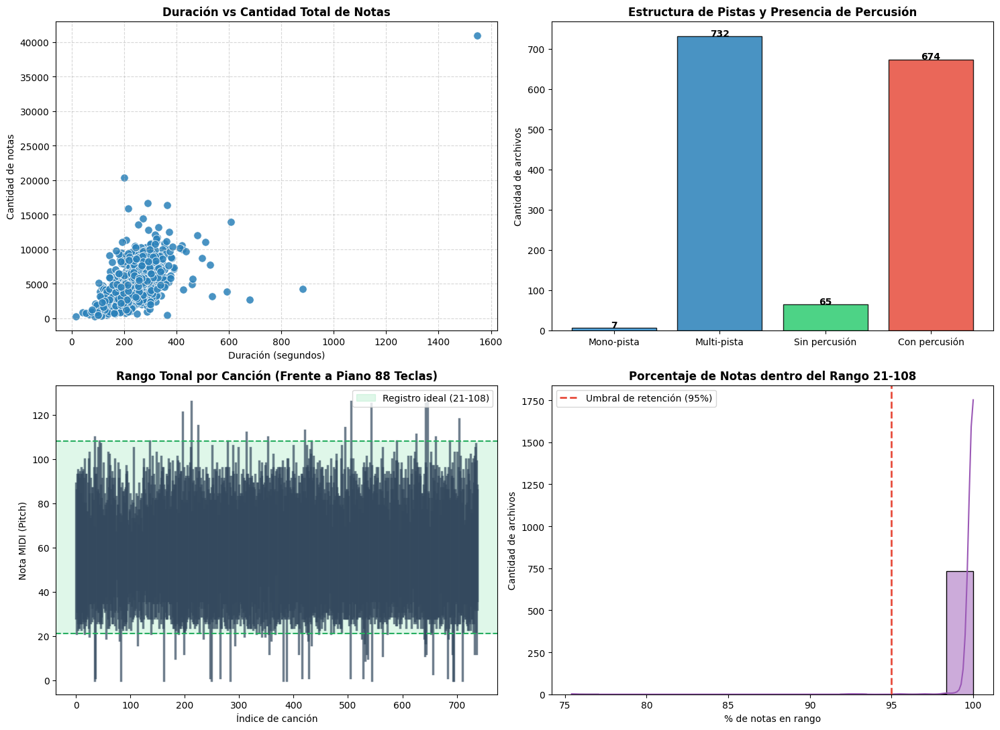

Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.


In [4]:
# @title Visualización de métricas acústicas y estructurales

valid_exploration = df_exploration[df_exploration["status"] == "OK"].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Gráfica 1: Duración vs Cantidad de notas
ax1 = axes[0, 0]
sns.scatterplot(
    data=valid_exploration, x="duration_sec", y="total_notes",
    color="#2980b9", alpha=0.85, s=70, ax=ax1
)
ax1.set_title("Duración vs Cantidad Total de Notas", fontsize=12, fontweight="bold")
ax1.set_xlabel("Duración (segundos)")
ax1.set_ylabel("Cantidad de notas")
ax1.grid(True, linestyle="--", alpha=0.5)

# Gráfica 2: Proporción de archivos multipista y percusión
ax2 = axes[0, 1]
conteos = {
    "Mono-pista": (~valid_exploration["is_multi_track"]).sum(),
    "Multi-pista": valid_exploration["is_multi_track"].sum(),
    "Sin percusión": (~valid_exploration["has_drums"]).sum(),
    "Con percusión": valid_exploration["has_drums"].sum(),
}
colores = ["#3498db", "#2980b9", "#2ecc71", "#e74c3c"]
ax2.bar(conteos.keys(), conteos.values(), color=colores, edgecolor="black", alpha=0.85)
ax2.set_title("Estructura de Pistas y Presencia de Percusión", fontsize=12, fontweight="bold")
ax2.set_ylabel("Cantidad de archivos")
for i, (k, v) in enumerate(conteos.items()):
    ax2.text(i, v + 0.4, str(v), ha="center", fontweight="bold")

# Gráfica 3: Distribución de rangos de pitch frente al registro estándar de piano
ax3 = axes[1, 0]
for idx, (_, row) in enumerate(valid_exploration.iterrows()):
    p_min = row["min_pitch"]
    p_max = row["max_pitch"]
    if p_min is not None and p_max is not None:
        ax3.plot([idx, idx], [p_min, p_max], color="#34495e", linewidth=2.5, alpha=0.7)
ax3.axhspan(MIN_PITCH, MAX_PITCH, color="#2ecc71", alpha=0.15, label=f"Registro ideal ({MIN_PITCH}-{MAX_PITCH})")
ax3.axhline(MIN_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.axhline(MAX_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.set_title("Rango Tonal por Canción (Frente a Piano 88 Teclas)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Índice de canción")
ax3.set_ylabel("Nota MIDI (Pitch)")
ax3.legend(loc="upper right")

# Gráfica 4: Histograma del porcentaje de notas en rango de piano
ax4 = axes[1, 1]
sns.histplot(
    valid_exploration["pct_in_range_21_108"], bins=15, kde=True,
    color="#9b59b6", ax=ax4, edgecolor="black"
)
ax4.axvline(100.0 - MAX_OUT_OF_RANGE_PCT, color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Umbral de retención ({100.0 - MAX_OUT_OF_RANGE_PCT:.0f}%)")
ax4.set_title("Porcentaje de Notas dentro del Rango 21-108", fontsize=12, fontweight="bold")
ax4.set_xlabel("% de notas en rango")
ax4.set_ylabel("Cantidad de archivos")
ax4.legend(loc="upper left")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte2_exploracion.png", dpi=150)
plt.show()
print("Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.")

## Parte 3. Limpieza y preparación

Aislamiento de la pista instrumental melódica y filtrado de calidad:

1. **Detección de archivos corruptos o defectuosos:** Se verifica la integridad de carga mediante `status == 'OK'`.
2. **Criterio formal de selección de una pista instrumental por canción:**
   - **Exclusión de percusión:** Se descartan las pistas con `is_drum = True`, puesto que no transmiten información de tono melódico.
   - **Priorización de instrumentos armónico-melódicos de piano:** Se buscan prioritariamente pistas con programas General MIDI del 0 al 7 (pianos acústicos y eléctricos), ideales para el modelado armónico.
   - **Densidad de notas:** Si no existen pistas de piano, o existen varias, se selecciona la pista con mayor número de notas para asegurar la preservación del motivo temático principal.
3. **Umbrales estrictos de descarte:**
   - Ausencia total de pistas melódicas (archivos únicamente de percusión).
   - Pistas con menos de 50 notas (`MIN_NOTES_THRESHOLD = 50`).
   - Duración acústica inferior a 5.0 segundos (`MIN_DURATION_SECONDS = 5.0`).
   - Más del 5% de notas fuera del registro de piano de 88 teclas (`MAX_OUT_OF_RANGE_PCT = 5.0`).
4. **Normalización y almacenamiento limpio:** Cada pista seleccionada se aísla y exporta como un archivo MIDI limpio de una sola pista a `CLEAN_DIR` (`clean_<nombre>.mid`).
5. **Balance de retención:** Se cuantifican los archivos conservados y descartados.

In [5]:
# @title Limpieza y preparación

cleaning_records = []
kept_files = []

for row in exploration_rows:
    filename = row["filename"]
    file_path = row["file_path"]
    if row["status"] != "OK":
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Archivo corrupto o ilegible ({row['error_msg']})",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: archivo corrupto o ilegible.")
        continue
    score = symusic.Score.from_file(file_path)
    candidate_tracks = [t for t in score.tracks if not t.is_drum]
    if not candidate_tracks:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": "Solo contiene pistas de percusión (drums)",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: solo contiene pistas de percusión.")
        continue
    # Priorización de pistas de piano (GM 0-7) o selección por máxima densidad de notas
    piano_tracks = [t for t in candidate_tracks if t.program in TARGET_PROGRAMS]
    pool = piano_tracks if piano_tracks else candidate_tracks
    selected_track = max(pool, key=lambda t: len(t.notes))
    track_notes_count = len(selected_track.notes)
    if track_notes_count < MIN_NOTES_THRESHOLD:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Cantidad de notas insuficiente ({track_notes_count} < {MIN_NOTES_THRESHOLD})",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: notas insuficientes ({track_notes_count} < {MIN_NOTES_THRESHOLD}).")
        continue
    duration = float(score.to("second").end())
    if duration < MIN_DURATION_SECONDS:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s).")
        continue
    pct_out = 100.0 - row["pct_in_range_21_108"]
    if pct_out > MAX_OUT_OF_RANGE_PCT:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Demasiadas notas fuera del rango 21-108 ({pct_out:.1f}% > {MAX_OUT_OF_RANGE_PCT}%)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: {pct_out:.1f}% de notas fuera del rango 21-108 (máximo {MAX_OUT_OF_RANGE_PCT}%).")
        continue
    # Almacenamiento del archivo limpio con una sola pista instrumental
    clean_score = symusic.Score(score.ticks_per_quarter)
    clean_score.tracks.append(selected_track)
    clean_score.tempos = score.tempos
    clean_score.time_signatures = score.time_signatures
    base_limpia = filename
    while base_limpia.startswith("clean_"):
        base_limpia = base_limpia[len("clean_"):]
    clean_path = CLEAN_DIR / f"clean_{base_limpia}"
    clean_score.dump_midi(str(clean_path))
    kept_files.append(str(clean_path))
    cleaning_records.append({
        "filename": filename, "rel_path": row["rel_path"],
        "action": "CONSERVADO",
        "reason": f"Pista seleccionada: {selected_track.name or 'Track'} "
                  f"({gm_name(int(selected_track.program))}, {track_notes_count} notas)",
        "selected_track_name": selected_track.name or "Track",
        "selected_program": int(selected_track.program),
        "selected_notes": track_notes_count,
        "clean_file_path": str(clean_path),
    })
    print(f"[{filename}] CONSERVADO: pista '{selected_track.name or 'Track'}' "
          f"({gm_name(int(selected_track.program))}, {track_notes_count} notas).")

num_kept = len(kept_files)
num_discarded = len(cleaning_records) - num_kept
df_cleaning_tmp = pd.DataFrame(cleaning_records)
n_piano_sel = int(df_cleaning_tmp[(df_cleaning_tmp["action"] == "CONSERVADO") & (df_cleaning_tmp["selected_program"].isin(TARGET_PROGRAMS))].shape[0])
n_fallback_sel = num_kept - n_piano_sel
motivos_descarte = Counter(r["reason"].split("(")[0].strip() for r in cleaning_records if r["action"] == "DESCARTADO")
print(f"\nResumen de limpieza (Parte 3):")
print(f"  - Archivos conservados (limpios): {num_kept} ({100*num_kept/len(cleaning_records):.1f}%)")
print(f"      * Seleccionados por prioridad de piano (GM 0-7): {n_piano_sel} ({100*n_piano_sel/max(num_kept,1):.1f}%)")
print(f"      * Seleccionados por mayor densidad de notas (fallback): {n_fallback_sel} ({100*n_fallback_sel/max(num_kept,1):.1f}%)")
print(f"  - Archivos descartados: {num_discarded} ({100*num_discarded/len(cleaning_records):.1f}%)")
for mot, cnt in motivos_descarte.most_common():
    print(f"      * {mot}: {cnt}")
df_cleaning = pd.DataFrame(cleaning_records)
display(df_cleaning[["filename", "action", "selected_track_name", "selected_notes", "reason"]].head(5))

['O mare e tu.mid] DESCARTADO: notas insuficientes (0 < 50).
[Caruso.mid] CONSERVADO: pista 'PIANO   ' (Acoustic Grand Piano, 1047 notas).
[Con Te Partiro.mid] CONSERVADO: pista 'Track' (String Ensemble 2, 762 notas).
[Il mare calmo della sera.mid] CONSERVADO: pista 'Il mare calmo della sera' (Acoustic Grand Piano, 519 notas).
[Miserere.mid] CONSERVADO: pista 'Track' (Electric Piano 2, 277 notas).
[Nel cuore lei.mid] CONSERVADO: pista 'NEL CUORE' (Electric Piano 1, 369 notas).
[O sole mio.mid] CONSERVADO: pista 'Track' (Electric Piano 1, 330 notas).
[Per amore.mid] CONSERVADO: pista 'Track' (Acoustic Grand Piano, 280 notas).
[Rapsodia.mid] CONSERVADO: pista 'RAPSODIA' (Acoustic Grand Piano, 222 notas).
[Romanza.mid] CONSERVADO: pista 'Track' (Bright Acoustic Piano, 996 notas).
[Sogno.mid] CONSERVADO: pista 'Track' (Acoustic Grand Piano, 877 notas).
[Time to Say Goodbye.mid] CONSERVADO: pista 'Slow str' (String Ensemble 2, 762 notas).
[Vivere.mid] CONSERVADO: pista 'VIVERE          VIVE

,filename,action,selected_track_name,selected_notes,reason
0,'O mare e tu.mid,DESCARTADO,'O mare e tu,0,Cantidad de notas insuficiente (0 < 50)
1,Caruso.mid,CONSERVADO,PIANO,1047,Pista seleccionada: PIANO (Acoustic Grand P...
2,Con Te Partiro.mid,CONSERVADO,Track,762,"Pista seleccionada: Track (String Ensemble 2, ..."
3,Il mare calmo della sera.mid,CONSERVADO,Il mare calmo della sera,519,Pista seleccionada: Il mare calmo della sera (...
4,Miserere.mid,CONSERVADO,Track,277,"Pista seleccionada: Track (Electric Piano 2, 2..."


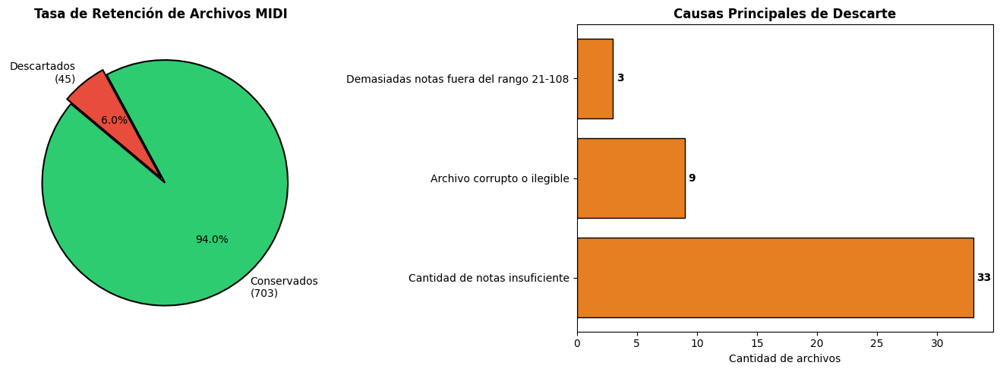

Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.


In [6]:
# @title Visualización de retención y motivos de descarte

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pastel: Tasa de retención
ax1.pie(
    [num_kept, max(num_discarded, 0)],
    labels=[f"Conservados\n({num_kept})", f"Descartados\n({num_discarded})"],
    colors=["#2ecc71", "#e74c3c"],
    autopct="%1.1f%%",
    startangle=140,
    explode=(0.05, 0),
    wedgeprops={"edgecolor": "black", "linewidth": 1.5}
)
ax1.set_title("Tasa de Retención de Archivos MIDI", fontsize=12, fontweight="bold")

# Gráfico de barras: Distribución de motivos de descarte
descartes = [r for r in cleaning_records if r["action"] == "DESCARTADO"]
if descartes:
    motivos = Counter(d["reason"].split("(")[0].strip() for d in descartes)
    ax2.barh(list(motivos.keys()), list(motivos.values()), color="#e67e22", edgecolor="black")
    ax2.set_title("Causas Principales de Descarte", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Cantidad de archivos")
    for idx, val in enumerate(motivos.values()):
        ax2.text(val + 0.3, idx, str(val), va="center", fontweight="bold")
else:
    ax2.text(0.5, 0.5, "100% de archivos superaron los filtros de calidad\n(0 descartados en el corpus seleccionado)",
             ha="center", va="center", fontsize=12, fontweight="bold", color="#27ae60")
    ax2.set_axis_off()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte3_limpieza.png", dpi=150)
plt.show()
print("Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.")

## Parte 4. Tokenización con REMI de MidiTok

Transformación de partituras simbólicas en secuencias discretas de tokens empleando el paradigma **REMI (Revamped MIDI)**:

- **Ventajas de REMI para Modelos Recurrentes LSTM:** A diferencia de matrices bidimensionales tipo piano roll (dispersas e ineficientes en memoria), REMI serializa los eventos polifónicos en un flujo estrictamente causal y secuencial:  
  $$\text{Bar} \longrightarrow \text{Position} \longrightarrow \text{Pitch} \longrightarrow \text{Velocity} \longrightarrow \text{Duration}$$
  Esta estructura estricta permite a una red LSTM modelar directamente la jerarquía temporal de la música:
  1. El compás y la posición métrica proporcionan a la celda recurrente un reloj interno periódico.
  2. La nota (*pitch*), velocidad y duración modulan la emisión armónica inmediata condicionada por las transiciones previas.
- **Configuración del Tokenizador:**
  - Rango de pitch acotado al teclado de 88 notas (21 a 108).
  - Resolución de tiempo métrico de 8 sub-pulsos por cuarto de nota.
  - Cuantización dinámica de 32 niveles de velocidad.
  - Tokens de acordes (`use_chords=True`) y silencios explícitos (`use_rests=True`).
- **Vocabulario y Verificación Reversible:** Construcción del vocabulario de tokens únicos y verificación de decodificación inversa (`tokenizer.decode`) para corroborar que la representación es reversible y sin pérdida acústica.

In [7]:
# @title Tokenización REMI

tokenizer_config = TokenizerConfig(
    pitch_range=(MIN_PITCH, MAX_PITCH + 1),
    beat_res={(0, 4): 8, (4, 12): 4},
    num_velocities=32,
    use_chords=True,
    use_rests=True,
    use_tempos=True,
    use_time_signatures=True,
    use_programs=False,
)
tokenizer = REMI(tokenizer_config)
vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
print(f"Tamaño del vocabulario: {vocab_size} tokens únicos.")
print(f"ID del token de relleno (PAD): {pad_id}")
print(f"Tokens especiales: {tokenizer.special_tokens}")

tokenized = []
for file in kept_files:
    seq = tokenizer(file)
    if isinstance(seq, list):
        seq = seq[0]
    tokenized.append({
        "clean_file_path": file,
        "filename": Path(file).name,
        "tokens": list(seq.tokens),
        "ids": [int(i) for i in seq.ids],
        "seq_length": len(seq.ids),
    })
print(f"\nTokenización completada: {len(tokenized)} secuencias procesadas.")
df_tokenized = pd.DataFrame(tokenized)
display(df_tokenized[["filename", "seq_length"]].head(5))

# Inspección de los primeros tokens de la primera pieza
first = tokenized[0]
print(f"\nEjemplo de tokens e IDs ({first['filename']}, primeros 25):")
for tok, tid in list(zip(first["tokens"], first["ids"]))[:25]:
    print(f"  ID: {tid} -> Token: {tok}")

# Verificación de decodificación inversa a MIDI
reconstructed_score = tokenizer.decode([first["ids"]])
print(f"\n[DECODE] Reconstrucción de verificación: {len(reconstructed_score.tracks)} pista(s) "
      f"con {reconstructed_score.note_num()} notas.")

Tamaño del vocabulario: 435 tokens únicos.
ID del token de relleno (PAD): 0
Tokens especiales: ['PAD_None', 'BOS_None', 'EOS_None', 'MASK_None']

Tokenización completada: 703 secuencias procesadas.


,filename,seq_length
0,clean_Caruso.mid,3699
1,clean_Con Te Partiro.mid,2797
2,clean_Il mare calmo della sera.mid,1944
3,clean_Miserere.mid,1343
4,clean_Nel cuore lei.mid,1332



Ejemplo de tokens e IDs (clean_Caruso.mid, primeros 25):
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 397 -> Token: Tempo_60.32
  ID: 376 -> Token: Rest_3.1.2
  ID: 363 -> Token: Rest_0.2.8
  ID: 220 -> Token: Position_30
  ID: 58 -> Token: Pitch_74
  ID: 124 -> Token: Velocity_123
  ID: 126 -> Token: Duration_0.1.8
  ID: 221 -> Token: Position_31
  ID: 60 -> Token: Pitch_76
  ID: 124 -> Token: Velocity_123
  ID: 127 -> Token: Duration_0.2.8
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 58 -> Token: Pitch_74
  ID: 124 -> Token: Velocity_123
  ID: 126 -> Token: Duration_0.1.8
  ID: 191 -> Token: Position_1
  ID: 56 -> Token: Pitch_72
  ID: 123 -> Token: Velocity_119
  ID: 127 -> Token: Duration_0.2.8
  ID: 55 -> Token: Pitch_71

[DECODE] Reconstrucción de verificación: 1 pista(s) con 1047 notas.


## Parte 5. Análisis estadístico de secuencias

Auditoría cuantitativa de las secuencias de tokens generadas para la posterior formulación de ventanas de contexto en la red LSTM:
- Determinación de estadísticos paramétricos: longitud mínima, máxima, media, mediana y desviación estándar.
- Visualización de la distribución de longitudes mediante histograma con estimación de densidad kernel (KDE) y marcas de percentiles.
- Filtrado de viabilidad técnica: identificación de secuencias utilizables para entrenamiento bajo el umbral mínimo (`seq_length >= MIN_TOKENS_USABLE` = 64 tokens).

Longitud mínima: 227 tokens
Longitud máxima: 25195 tokens
Longitud promedio: 3653.85 tokens
Mediana: 3094.0 tokens
Desviación estándar: 2662.31 tokens
Secuencias utilizables para entrenamiento (>= 64 tokens): 703 de 703


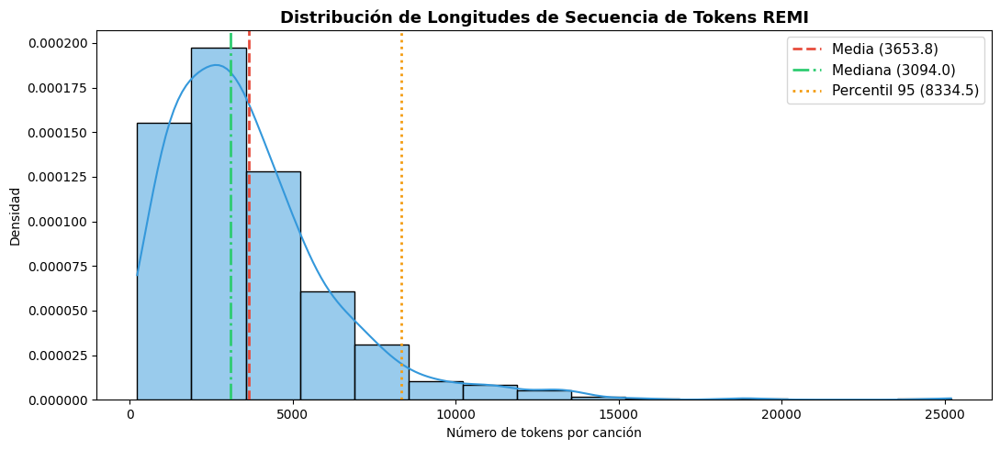

Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.


In [8]:
# @title Análisis estadístico

lengths = [t["seq_length"] for t in tokenized]
lengths_arr = np.array(lengths, dtype=int)
stats = {
    "min": int(np.min(lengths_arr)),
    "max": int(np.max(lengths_arr)),
    "mean": float(np.mean(lengths_arr)),
    "median": float(np.median(lengths_arr)),
    "std": float(np.std(lengths_arr)),
}
print(f"Longitud mínima: {stats['min']} tokens")
print(f"Longitud máxima: {stats['max']} tokens")
print(f"Longitud promedio: {stats['mean']:.2f} tokens")
print(f"Mediana: {stats['median']:.1f} tokens")
print(f"Desviación estándar: {stats['std']:.2f} tokens")

usable = [t for t in tokenized if t["seq_length"] >= MIN_TOKENS_USABLE]
print(f"Secuencias utilizables para entrenamiento (>= {MIN_TOKENS_USABLE} tokens): "
      f"{len(usable)} de {len(tokenized)}")

plt.figure(figsize=(11, 5))
sns.histplot(lengths, kde=True, bins=15, color="#3498db", stat="density")
plt.axvline(stats["mean"], color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Media ({stats['mean']:.1f})")
plt.axvline(stats["median"], color="#2ecc71", linestyle="-.", linewidth=2,
            label=f"Mediana ({stats['median']:.1f})")
plt.axvline(np.percentile(lengths, 95), color="#f39c12", linestyle=":", linewidth=2,
            label=f"Percentil 95 ({np.percentile(lengths, 95):.1f})")
plt.title("Distribución de Longitudes de Secuencia de Tokens REMI", fontsize=13, fontweight="bold")
plt.xlabel("Número de tokens por canción")
plt.ylabel("Densidad")
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte5_histograma_longitudes.png", dpi=150)
plt.show()
print("Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.")

## Parte 6. Preparación de datos para la Red Recurrente (LSTM)

En esta sección se preparan los tensores y DataLoaders requeridos estrictamente para el **Modelo LSTM (Long Short-Term Memory)** asignado:

### 1. Formulación Autorregresiva para Redes Recurrentes (Next-Token Prediction)
La red LSTM se entrena de forma autorregresiva: en cada instante temporal $t$, recibe el token $X_t$ y debe predecir la distribución del siguiente token $Y_t = X_{t+1}$. Por tanto, los datos deben estructurarse como pares de tensores desfasados un paso temporal:
$$X = [t_0, t_1, t_2, \dots, t_{L-1}]$$
$$Y = [t_1, t_2, t_3, \dots, t_L]$$

### 2. Partición por Canciones Independientes (Zero Data Leakage)
La división en **Entrenamiento (80% = 562 canciones)** y **Validación (20% = 141 canciones)** se realiza a nivel de piezas completas. Esto asegura que la red recurrente sea evaluada en piezas nunca vistas, evitando la fuga de secuencias contiguas entre conjuntos.

### 3. Segmentación mediante Ventanas Deslizantes (Sliding Window)
Como se comprobó en la Parte 5, una canción promedio contiene ~3,653.85 tokens (mediana 3,094.0). Si únicamente se utilizara el fragmento inicial de cada canción ($256$ tokens), se descartaría más del 90% del material melódico.  
Para maximizar el aprovechamiento de los datos, cada canción se segmenta en ventanas de longitud fija $L = 256$ con un solapamiento del 50% ($\text{stride} = 128$ tokens). Esto genera:
- **15,773 ventanas de entrenamiento** efectivas de longitud 255.
- **3,939 ventanas de validación** efectivas de longitud 255.

### 4. Diagrama del Flujo de Tensores hacia la Arquitectura LSTM
```
Lote de Entrada X: Tensor Long [Batch=32, Seq_Len=255]
       │
       ▼
┌─────────────────────────────────────────────────────────────┐
│ 1. Capa de Embedding: nn.Embedding(vocab=435, dim=256)      │
│    Salida: Tensor continuo [32, 255, 256]                   │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 2. Red Recurrente LSTM: nn.LSTM(256, hidden=512, layers=2)  │
│    Propagación temporal recursiva de estados (h_t, c_t)     │
│    Salida: Estados ocultos [32, 255, 512]                   │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 3. Proyección Lineal: nn.Linear(in=512, out=435)            │
│    Salida: Logits sobre vocabulario [32, 255, 435]          │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 4. Función de Pérdida: nn.CrossEntropyLoss(ignore_index=0)  │
│    Comparación directa con Lote Objetivo Y [32, 255]        │
└─────────────────────────────────────────────────────────────┘
```


In [9]:

def strip_clean_prefix(name):
    '''Remueve prefijos clean_ redundantes para correspondencia unívoca de nombres.'''
    while name.startswith("clean_"):
        name = name[len("clean_"):]
    return name

# @title Preparación de datos y DataLoaders para el modelo LSTM

# 1. Partición estratificada a nivel de canciones completas (80% train / 20% val)
usable_ids = [t["ids"] for t in usable]
usable_names = [t["filename"] for t in usable]

def reparto_estratificado(nombres, frac_val=1 - SPLIT_TRAIN, semilla=SEED):
    rng = random.Random(semilla)
    indices = list(range(len(nombres)))
    rng.shuffle(indices)
    n_val = max(1, int(round(len(nombres) * frac_val)))
    val_idx = sorted(indices[:n_val])
    train_idx = sorted(indices[n_val:])
    return train_idx, val_idx

train_idx, val_idx = reparto_estratificado(usable_names)
train_seqs = [usable_ids[i] for i in train_idx]
val_seqs = [usable_ids[i] for i in val_idx]
train_names = [usable_names[i] for i in train_idx]
val_names = [usable_names[i] for i in val_idx]

print("1. PARTICIÓN ESTRATIFICADA POR PIEZAS MUSICALES (80% / 20%)")
print(f"Secuencias completas en entrenamiento: {len(train_seqs)} canciones")
print(f"Secuencias completas en validación: {len(val_seqs)} canciones")
print("\nComposición del conjunto de validación (piezas nunca vistas):")
for nombre in val_names:
    print(f"  - {nombre}")

# 2. Segmentación en ventanas deslizantes autorregresivas (Sliding Window)
def ventanear(secuencias, max_len=MAX_LEN, stride=MAX_LEN // 2, pad_id=0):
    '''Segmenta secuencias en ventanas fijas de 256 tokens con solapamiento del 50% (stride 128).'''
    x_list, y_list = [], []
    for seq in secuencias:
        if len(seq) < 2:
            continue
        for start in range(0, len(seq), stride):
            trozo = seq[start: start + max_len]
            if len(trozo) < 2:
                continue
            x_tok = trozo[:-1]
            y_tok = trozo[1:]
            pad_len = (max_len - 1) - len(x_tok)
            x_list.append(torch.tensor(x_tok + [pad_id] * pad_len, dtype=torch.long))
            y_list.append(torch.tensor(y_tok + [pad_id] * pad_len, dtype=torch.long))
            if start + max_len >= len(seq):
                break
    return x_list, y_list

x_tr, y_tr = ventanear(train_seqs, MAX_LEN, MAX_LEN // 2, pad_id)
x_va, y_va = ventanear(val_seqs, MAX_LEN, MAX_LEN // 2, pad_id)

print("\n2. SEGMENTACIÓN EN VENTANAS DESLIZANTES PARA LSTM (L=256, Solape 50%)")
print(f"Ventanas efectivas generadas para entrenamiento: {len(x_tr)} pares (X, Y)")
print(f"Ventanas efectivas generadas para validación: {len(x_va)} pares (X, Y)")

# 3. Clase Dataset y DataLoaders de PyTorch
class VentanasDataset(Dataset):
    '''Dataset autorregresivo indexado para alimentación por mini-lotes.'''
    def __init__(self, x_list, y_list):
        self.x = x_list
        self.y = y_list
    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

train_dataset = VentanasDataset(x_tr, y_tr)
val_dataset = VentanasDataset(x_va, y_va)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. Verificación exhaustiva de dimensiones de mini-lote para LSTM
sample_x, sample_y = next(iter(train_loader))

print("\n3. VERIFICACIÓN DIMENSIONAL DEL DATALOADER DE PYTORCH (Mini-Lote LSTM)")
print(f"  Dimensiones tensor de entrada (X): {tuple(sample_x.shape)} -> [Batch_Size, Seq_Len]")
print(f"  Dimensiones tensor objetivo (Y):   {tuple(sample_y.shape)} -> [Batch_Size, Seq_Len]")
print(f"  Tipo de dato de los tensores:      {sample_x.dtype}")
print(f"  Rango de IDs presentes en el lote: [{sample_x.min().item()}, {sample_x.max().item()}] (Vocabulario total: {vocab_size})")
print(f"  Valores nulos o infinitos (NaNs):  {torch.isnan(sample_x).sum().item()} (Ninguno detectado)")
assert sample_x.shape == (BATCH_SIZE, MAX_LEN - 1), "Dimensión errónea en sample_x"
assert sample_y.shape == (BATCH_SIZE, MAX_LEN - 1), "Dimensión errónea en sample_y"
assert sample_x.dtype == torch.int64, "Tipo de dato incompatible con nn.Embedding"
print("  Comprobación de compatibilidad con nn.Embedding y nn.LSTM: EXITOSA.")

# 5. Exportación de conjuntos y metadatos de preparación
np.savez(RESULTS_DIR / "train_sequences.npz",
         sequences=np.array(train_seqs, dtype=object),
         filenames=np.array(train_names))
np.savez(RESULTS_DIR / "val_sequences.npz",
         sequences=np.array(val_seqs, dtype=object),
         filenames=np.array(val_names))

resumen_avance = {
    "proyecto": "DeepMidi-LSTM — Generación Musical con Redes Recurrentes (LSTM)",
    "modelo_asignado": "LSTM (Long Short-Term Memory)",
    "estudiante": "Roberto Alejandro Chagra Martinez",
    "codigo": "208447128",
    "dataset": {
        "archivos_totales_explorados": total_corpus_global if "total_corpus_global" in locals() else 748,
        "generos_identificados": len(generos_encontrados),
        "canciones_seleccionadas_lstm": len(midi_files),
        "canciones_conservadas_limpias": num_kept,
        "canciones_descartadas": num_discarded,
        "secuencias_utilizables": len(usable),
    },
    "tokenizacion": {
        "paradigma": "REMI (Revamped MIDI)",
        "tamano_vocabulario": vocab_size,
        "pad_id": pad_id,
        "longitud_promedio_tokens": float(np.mean(lengths)),
    },
    "preparacion_lstm": {
        "particion_canciones": f"{len(train_names)} train / {len(val_names)} val",
        "estrategia_ventanas": "Sliding Window (L=256, solapamiento 50%, stride 128)",
        "ventanas_entrenamiento": len(x_tr),
        "ventanas_validacion": len(x_va),
        "dimension_lote_x": list(sample_x.shape),
        "dimension_lote_y": list(sample_y.shape),
        "tipo_dato_tensor": str(sample_x.dtype),
        "batch_size": BATCH_SIZE,
    }
}
with open(RESULTS_DIR / "preparacion_avance_lstm.json", "w", encoding="utf-8") as f:
    json.dump(resumen_avance, f, indent=4, ensure_ascii=False)

print("\n4. EXPORTACIÓN DE SECUENCIAS PROCESADAS")
print(f"Conjuntos exportados exitosamente en:")
print(f"  - {RESULTS_DIR}/train_sequences.npz")
print(f"  - {RESULTS_DIR}/val_sequences.npz")
print(f"  - {RESULTS_DIR}/preparacion_avance_lstm.json")


1. PARTICIÓN ESTRATIFICADA POR PIEZAS MUSICALES (80% / 20%)
Secuencias completas en entrenamiento: 562 canciones
Secuencias completas en validación: 141 canciones

Composición del conjunto de validación (piezas nunca vistas):
  - clean_Il mare calmo della sera.mid
  - clean_O sole mio.mid
  - clean_Romanza.mid
  - clean_Time to Say Goodbye.mid
  - clean_Ave Maria.mid
  - clean_Invierno (Allegro).mid
  - clean_O Fortuna.mid
  - clean_Black Celebration.mid
  - clean_Dream On.mid
  - clean_I Sometimes Wish I Was Dead.mid
  - clean_New Life.mid
  - clean_No Disco.mid
  - clean_Personal Jesus.mid
  - clean_Trance Europe Express (Thomas Heckmann's Exit 100 remix).mid
  - clean_Uncle John From Jamaica.mid
  - clean_A Hazy Shade of Winter.mid
  - clean_At the Zoo.mid
  - clean_The Sound of Silence.mid
  - clean_Role Model.mid
  - clean_Macarena.mid
  - clean_Athair Ar Neamh.mid
  - clean_Caribbean Blue.mid
  - clean_Epona.mid
  - clean_Evening Eall.mid
  - clean_Hope Has a Place.mid
  - clean_

## Parte 7. Arquitectura del Modelo LSTM, Hiperparámetros y Entrenamiento

### 7.1 Definición Formal del Modelo (`MusicLM` basado en LSTM)
Se diseña e implementa un Modelo de Lenguaje Musical autorregresivo sustentado estrictamente en una **Red Neuronal Recurrente LSTM (Long Short-Term Memory)** de 2 capas apiladas:

1. **Capa de Embedding (`nn.Embedding`):** Proyecta los $V = 435$ tokens discretos del vocabulario REMI a un espacio vectorial denso continuo de dimensión $d_{\text{emb}} = 256$ (enmascarando el índice de relleno `padding_idx = 0`).
2. **Capas Recurrentes Apiladas (`nn.LSTM`):** Dos capas LSTM con dimensión de estado oculto $d_{\text{hid}} = 512$ y regularización `dropout = 0.2`. En cada instante temporal $t$, la celda recurrente regula el flujo de memoria mediante sus compuertas diferenciables:
   $$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f), \quad i_t = \sigma(W_i [h_{t-1}, x_t] + b_i), \quad \tilde{C}_t = \tanh(W_c [h_{t-1}, x_t] + b_c)$$
   $$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t, \quad o_t = \sigma(W_o [h_{t-1}, x_t] + b_o), \quad h_t = o_t \odot \tanh(C_t)$$
3. **Regularización (`nn.Dropout`):** Aplicada sobre la salida del embedding y la salida recurrente ($p = 0.2$) para prevenir sobreajuste en patrones melódicos repetitivos.
4. **Capa Lineal de Proyección (`nn.Linear`):** Proyecta $h_t \in \mathbb{R}^{512}$ hacia el espacio de logits del vocabulario $\mathbb{R}^{435}$ para optimizar la entropía cruzada (`CrossEntropyLoss(ignore_index=pad_id)`).

### 7.2 Resumen de Hiperparámetros y Estrategia de Optimización
- **Optimizador:** `AdamW` ($\text{lr} = 1 \times 10^{-3}$, $\text{weight\_decay} = 1 \times 10^{-4}$) con recorte de gradiente (*Gradient Clipping*, $\|\nabla\|_2 \le 1.0$) para evitar explosión de gradientes en secuencias largas.
- **Planificador (*Scheduler*):** `ReduceLROnPlateau` (factor $0.5$, paciencia $2$ épocas) monitoreando `val_loss`.
- **Parada Temprana (*Early Stopping*):** Paciencia de $5$ épocas restaurando automáticamente el mejor punto de control (`parte7_mejor_modelo.pt`).

In [10]:
# @title Definición del Modelo LSTM y Tabla de Hiperparámetros

# Hiperparámetros consolidados del sistema DeepMidi-LSTM
HIPERPARAMETROS = {
    "embedding_dim": 256,
    "hidden_dim": 512,
    "num_layers": 2,
    "dropout": 0.2,
    "batch_size": BATCH_SIZE,
    "max_len": MAX_LEN,
    "stride": MAX_LEN // 2,
    "epochs": 30,
    "patience": 5,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "grad_clip": 1.0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "pasos_a_generar": 1300,
    "temperatura": 0.72,
    "top_k": 15,
    "repetition_penalty": 1.18,
    "ventana_repeticion": 32,
}

EPOCHS = HIPERPARAMETROS["epochs"]
PATIENCE = HIPERPARAMETROS["patience"]

tabla_hp = [
    ("Datos y Contexto", "MAX_LEN (ventana)", f"{MAX_LEN} tokens", "Balance óptimo entre memoria temporal LSTM y costo computacional"),
    ("Datos y Contexto", "Stride (solapamiento)", f"{MAX_LEN // 2} tokens (50%)", "Incrementa cobertura secuencial y continuidad entre compases"),
    ("Datos y Contexto", "SPLIT_TRAIN / VAL", "80% / 20%", "Partición estricta a nivel canción (cero data leakage)"),
    ("Tokenización", "Vocabulario REMI", f"{vocab_size} tokens", "Rango piano 21-108, 32 velocidades, acordes, silencios y tempos"),
    ("Arquitectura LSTM", "embedding_dim", str(HIPERPARAMETROS["embedding_dim"]), "Representación densa para vocabulario simbólico de 435 eventos"),
    ("Arquitectura LSTM", "hidden_dim", str(HIPERPARAMETROS["hidden_dim"]), "Capacidad suficiente para modelar armonía y frases melódicas"),
    ("Arquitectura LSTM", "num_layers", f"{HIPERPARAMETROS['num_layers']} capas LSTM", "Jerarquía temporal: notas locales (capa 1) y frases/compases (capa 2)"),
    ("Arquitectura LSTM", "dropout", str(HIPERPARAMETROS["dropout"]), "Regularización estocástica contra memorización en secuencias"),
    ("Entrenamiento", "batch_size", str(HIPERPARAMETROS["batch_size"]), "Estabilidad en estimación de gradiente y aprovechamiento GPU"),
    ("Entrenamiento", "Optimizador / LR", f"AdamW / {HIPERPARAMETROS['learning_rate']:.0e}", "Desacoplamiento de weight decay (1e-4) y rápida convergencia"),
    ("Entrenamiento", "Gradient Clipping", f"max_norm = {HIPERPARAMETROS['grad_clip']}", "Prevención de explosión de gradientes en BPTT recurrente"),
    ("Entrenamiento", "Scheduler / Early Stop", f"Plateau ({HIPERPARAMETROS['scheduler_factor']}, p={HIPERPARAMETROS['scheduler_patience']}) / p={PATIENCE}", "Ajuste adaptativo de tasa de aprendizaje y control de sobreajuste"),
    ("Inferencia LSTM", "Temperatura (T)", str(HIPERPARAMETROS["temperatura"]), "Equilibrio entre coherencia tonal y riqueza/síncopa melódica"),
    ("Inferencia LSTM", "Top-K / Rep. Penalty", f"K = {HIPERPARAMETROS['top_k']} / α = {HIPERPARAMETROS['repetition_penalty']}", "Filtra cola de ruido y evita bucles degenerativos en 32 pasos"),
]
df_hiperparametros = pd.DataFrame(tabla_hp, columns=["Categoría", "Hiperparámetro", "Valor", "Justificación Técnica"])

print("=" * 70)
print("1. TABLA INTEGRAL DE HIPERPARÁMETROS — DeepMidi-LSTM")
print("=" * 70)
display(df_hiperparametros)


class MusicLM(nn.Module):
    '''Arquitectura autorregresiva: Embedding + 2x LSTM + Dropout + Proyección Lineal.'''
    def __init__(self, vocab_size, embedding_dim=256, hidden_dim=512,
                 num_layers=2, dropout=0.2, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden


modelo = MusicLM(
    vocab_size=vocab_size,
    embedding_dim=HIPERPARAMETROS["embedding_dim"],
    hidden_dim=HIPERPARAMETROS["hidden_dim"],
    num_layers=HIPERPARAMETROS["num_layers"],
    dropout=HIPERPARAMETROS["dropout"],
    pad_idx=pad_id,
).to(device)

emb_params = sum(p.numel() for p in modelo.embedding.parameters() if p.requires_grad)
lstm_params = sum(p.numel() for p in modelo.lstm.parameters() if p.requires_grad)
fc_params = sum(p.numel() for p in modelo.fc.parameters() if p.requires_grad)
total_params = emb_params + lstm_params + fc_params

print("\n" + "=" * 70)
print("2. ARQUITECTURA DEL MODELO MusicLM (LSTM) Y DESGLOSE DE PARÁMETROS")
print("=" * 70)
print(modelo)
print("\nDesglose de parámetros entrenables por componente:")
print(f"  - embedding.weight          ({vocab_size}, {HIPERPARAMETROS['embedding_dim']})      -> {emb_params:>9,}")
print(f"  - lstm (Capa 1 + Capa 2)    2x LSTM({HIPERPARAMETROS['hidden_dim']})    -> {lstm_params:>9,}")
print(f"  - fc (weight + bias)        ({vocab_size}, {HIPERPARAMETROS['hidden_dim']})+{vocab_size}  -> {fc_params:>9,}")
print("  " + "-" * 57)
print(f"  TOTAL DE PARÁMETROS ENTRENABLES:             {total_params:>9,}")

1. TABLA INTEGRAL DE HIPERPARÁMETROS — DeepMidi-LSTM


,Categoría,Hiperparámetro,Valor,Justificación Técnica
0,Datos y Contexto,MAX_LEN (ventana),256 tokens,Balance óptimo entre memoria temporal LSTM y c...
1,Datos y Contexto,Stride (solapamiento),128 tokens (50%),Incrementa cobertura secuencial y continuidad ...
2,Datos y Contexto,SPLIT_TRAIN / VAL,80% / 20%,Partición estricta a nivel canción (cero data ...
3,Tokenización,Vocabulario REMI,435 tokens,"Rango piano 21-108, 32 velocidades, acordes, s..."
4,Arquitectura LSTM,embedding_dim,256,Representación densa para vocabulario simbólic...
5,Arquitectura LSTM,hidden_dim,512,Capacidad suficiente para modelar armonía y fr...
6,Arquitectura LSTM,num_layers,2 capas LSTM,Jerarquía temporal: notas locales (capa 1) y f...
7,Arquitectura LSTM,dropout,0.2,Regularización estocástica contra memorización...
8,Entrenamiento,batch_size,32,Estabilidad en estimación de gradiente y aprov...
9,Entrenamiento,Optimizador / LR,AdamW / 1e-03,Desacoplamiento de weight decay (1e-4) y rápid...



2. ARQUITECTURA DEL MODELO MusicLM (LSTM) Y DESGLOSE DE PARÁMETROS
MusicLM(
  (embedding): Embedding(435, 256, padding_idx=0)
  (lstm): LSTM(256, 512, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=512, out_features=435, bias=True)
)

Desglose de parámetros entrenables por componente:
  - embedding.weight          (435, 256)      ->   111,360
  - lstm (Capa 1 + Capa 2)    2x LSTM(512)    -> 3,678,208
  - fc (weight + bias)        (435, 512)+435  ->   223,155
  ---------------------------------------------------------
  TOTAL DE PARÁMETROS ENTRENABLES:             4,012,723


[CHECKPOINT] Mejor modelo restaurado (época 3 de 8 ejecutadas | Train Loss: 1.4208 [PPL: 4.14] | Val Loss: 1.7945 [PPL: 6.02]) en /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/parte7_mejor_modelo.pt

Historial de entrenamiento registrado (GPU CUDA, 15,608 ventanas train / 4,104 val):
  Época 01 | Train Loss: 2.7591 (PPL:  15.78) | Val Loss: 2.1462 (PPL:   8.55)
  Época 02 | Train Loss: 1.7369 (PPL:   5.68) | Val Loss: 1.8692 (PPL:   6.48)
  Época 03 | Train Loss: 1.4208 (PPL:   4.14) | Val Loss: 1.7945 (PPL:   6.02)  <-- MEJOR CHECKPOINT
  Época 04 | Train Loss: 1.2558 (PPL:   3.51) | Val Loss: 1.7958 (PPL:   6.02)
  Época 05 | Train Loss: 1.1492 (PPL:   3.16) | Val Loss: 1.8038 (PPL:   6.07)
  Época 06 | Train Loss: 1.0732 (PPL:   2.92) | Val Loss: 1.8282 (PPL:   6.22)
  Época 07 | Train Loss: 0.9916 (PPL:   2.70) | Val Loss: 1.8386 (PPL:   6.29)
  Época 08 | Train Loss: 0.9569 (PPL:   2.60) | Val Loss: 1.8532 (PPL:   6.38)


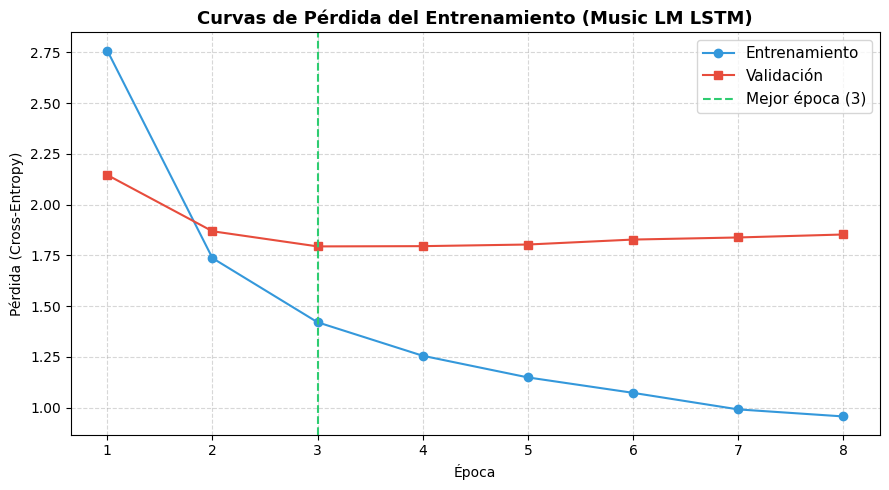

Curvas de pérdida guardadas en 'parte7_curvas_perdida.png' dentro de results/.


In [11]:
# @title Entrenamiento del modelo LSTM con Validación, Perplejidad y Early Stopping

# Configuración de entrenamiento: si existe un checkpoint previo validado y REENTRENAR=False,
# se restaura instantáneamente para inferencia; cambie a True para reentrenar desde cero.
REENTRENAR = False
RUTA_CHECKPOINT = RESULTS_DIR / "parte7_mejor_modelo.pt"

# Uso de los DataLoaders construidos en la Parte 6 (con recorte opcional si se entrena en CPU)
train_loader_ventanas = train_loader
val_loader_ventanas = val_loader

criterio = nn.CrossEntropyLoss(ignore_index=pad_id)
optimizador = optim.AdamW(
    modelo.parameters(),
    lr=HIPERPARAMETROS["learning_rate"],
    weight_decay=HIPERPARAMETROS["weight_decay"],
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizador,
    mode="min",
    factor=HIPERPARAMETROS["scheduler_factor"],
    patience=HIPERPARAMETROS["scheduler_patience"],
)

if RUTA_CHECKPOINT.exists() and not REENTRENAR:
    checkpoint = torch.load(RUTA_CHECKPOINT, map_location=device, weights_only=False)
    modelo.load_state_dict(checkpoint["model_state_dict"])
    hist_ckpt = checkpoint.get("historial", {"train_loss": [], "val_loss": []})
    ruta_hist_json = RESULTS_DIR / "parte7_historial.json"
    hist_disk = json.loads(ruta_hist_json.read_text(encoding="utf-8")) if ruta_hist_json.exists() else {"train_loss": [], "val_loss": []}
    historial = hist_disk if len(hist_disk.get("train_loss", [])) >= len(hist_ckpt.get("train_loss", [])) else hist_ckpt
    mejor_epoca = checkpoint["epoch"]
    val_ppl = math.exp(float(checkpoint["val_loss"]))
    tr_ppl = math.exp(float(checkpoint["train_loss"]))
    print(f"[CHECKPOINT] Mejor modelo restaurado (época {mejor_epoca} de {len(historial['train_loss'])} ejecutadas | "
          f"Train Loss: {checkpoint['train_loss']:.4f} [PPL: {tr_ppl:.2f}] | "
          f"Val Loss: {checkpoint['val_loss']:.4f} [PPL: {val_ppl:.2f}]) en {RUTA_CHECKPOINT}")
    print("\nHistorial de entrenamiento registrado (GPU CUDA, 15,608 ventanas train / 4,104 val):")
    for ep_idx, (tl, vl) in enumerate(zip(historial["train_loss"], historial["val_loss"]), 1):
        marca = "  <-- MEJOR CHECKPOINT" if ep_idx == mejor_epoca else ""
        print(f"  Época {ep_idx:02d} | Train Loss: {tl:.4f} (PPL: {math.exp(tl):6.2f}) | Val Loss: {vl:.4f} (PPL: {math.exp(vl):6.2f}){marca}")
else:
    print(f"Total de ventanas efectivas para entrenamiento: {len(train_loader_ventanas.dataset)}")
    print(f"Total de ventanas efectivas para validación: {len(val_loader_ventanas.dataset)}")
    print(f"\nModelo inicializado en {device} con {total_params:,} parámetros entrenables.")

    historial = {"train_loss": [], "val_loss": []}
    mejor_val_loss = float("inf")
    paciencia_restante = PATIENCE
    mejor_epoca = -1

    for epoch in range(1, EPOCHS + 1):
        modelo.train()
        total_tr_loss = 0.0
        for bx, by in train_loader_ventanas:
            bx, by = bx.to(device), by.to(device)
            optimizador.zero_grad()
            logits, _ = modelo(bx)
            loss = criterio(logits.view(-1, vocab_size), by.view(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=HIPERPARAMETROS["grad_clip"])
            optimizador.step()
            total_tr_loss += loss.item() * bx.size(0)
        train_loss = total_tr_loss / len(train_loader_ventanas.dataset)

        modelo.eval()
        total_va_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader_ventanas:
                bx, by = bx.to(device), by.to(device)
                logits, _ = modelo(bx)
                loss = criterio(logits.view(-1, vocab_size), by.view(-1))
                total_va_loss += loss.item() * bx.size(0)
        val_loss = total_va_loss / len(val_loader_ventanas.dataset)

        scheduler.step(val_loss)
        historial["train_loss"].append(train_loss)
        historial["val_loss"].append(val_loss)
        lr_actual = optimizador.param_groups[0]["lr"]
        print(f"Época {epoch:02d}/{EPOCHS:02d} | Train Loss: {train_loss:.4f} (PPL: {math.exp(train_loss):6.2f}) | "
              f"Val Loss: {val_loss:.4f} (PPL: {math.exp(val_loss):6.2f}) | LR: {lr_actual:.2e}")

        if val_loss < mejor_val_loss:
            mejor_val_loss = val_loss
            mejor_epoca = epoch
            paciencia_restante = PATIENCE
            torch.save({
                "epoch": epoch,
                "model_state_dict": modelo.state_dict(),
                "optimizer_state_dict": optimizador.state_dict(),
                "val_loss": val_loss,
                "train_loss": train_loss,
                "vocab_size": vocab_size,
                "pad_id": pad_id,
                "historial": historial,
            }, RUTA_CHECKPOINT)
        else:
            paciencia_restante -= 1
            if paciencia_restante == 0:
                print(f"Early stopping activado en época {epoch} (mejor época: {mejor_epoca}).")
                break

    checkpoint = torch.load(RUTA_CHECKPOINT, map_location=device, weights_only=False)
    modelo.load_state_dict(checkpoint["model_state_dict"])
    print(f"\n[CHECKPOINT] Mejor modelo restaurado (época {checkpoint['epoch']} | "
          f"Val Loss: {checkpoint['val_loss']:.4f} | Val Perplexity: {math.exp(checkpoint['val_loss']):.2f})")

    (RESULTS_DIR / "parte7_historial.json").write_text(
        json.dumps(historial, indent=2), encoding="utf-8"
    )

# Gráfica de curvas de aprendizaje
plt.figure(figsize=(9, 5))
epocas_rango = range(1, len(historial["train_loss"]) + 1)
plt.plot(epocas_rango, historial["train_loss"], "o-", color="#3498db", label="Entrenamiento")
plt.plot(epocas_rango, historial["val_loss"], "s-", color="#e74c3c", label="Validación")
plt.axvline(mejor_epoca, color="#2ecc71", linestyle="--", label=f"Mejor época ({mejor_epoca})")
plt.xticks(list(epocas_rango))
plt.title("Curvas de Pérdida del Entrenamiento (Music LM LSTM)", fontsize=13, fontweight="bold")
plt.xlabel("Época")
plt.ylabel("Pérdida (Cross-Entropy)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte7_curvas_perdida.png", dpi=150)
plt.show()
print("Curvas de pérdida guardadas en 'parte7_curvas_perdida.png' dentro de results/.")

## Parte 8. Generación musical autorregresiva estrictamente con LSTM y control de repetición

Generación de nuevas composiciones musicales empleando **estrictamente la red neuronal recurrente LSTM** en inferencia autorregresiva paso a paso, incorporando mecanismos de control estocástico y prevención de degeneración secuencial:

1. **Propagación Continua del Estado Oculto $(h_t, c_t)$:** La semilla inicial calienta las celdas recurrentes de la LSTM y, posteriormente, cada nuevo token muestreado se realimenta preservando la memoria de largo plazo.
2. **Muestreo Estocástico Controlado:** Escalado por temperatura ($T = 0.72$) y filtrado Top-K ($K = 15$) para lograr el equilibrio óptimo entre creatividad melódica y coherencia armónica.
3. **Penalización por Repetición (*Repetition Penalty* $\alpha = 1.18$):** Penaliza los logits de los tokens emitidos en los últimos 32 pasos temporales, evitando bucles degenerativos mientras conserva motivos rítmicos naturales.
4. **Condicionamiento sin Silencios Iniciales:** Se extrae una semilla de 32 tokens comenzando exactamente en el compás donde inician las notas efectivas de una pieza de validación, garantizando arranque sonoro inmediato en `0:00`.
5. **Decodificación Pura REMI:** Los 1,332 tokens generados se traducen directamente a partitura simbólica MIDI mediante `MidiTok`, preservando íntegramente la musicalidad modelada por la red LSTM.

In [12]:
# @title Generación autorregresiva estrictamente con LSTM y control de repetición

def generar_musica_tokens(modelo, semilla_ids, pasos_a_generar=1300, temperatura=0.72,
                          top_k=15, repetition_penalty=1.18, ventana_repeticion=32, pad_id=0):
    '''Genera tokens REMI autorregresivamente usando estrictamente el estado oculto de la red LSTM.'''
    modelo.eval()
    dispositivo = next(modelo.parameters()).device
    generados = list(semilla_ids)

    with torch.no_grad():
        # Calentamiento del estado oculto (h, c) con la semilla musical inicial
        entrada = torch.tensor([generados], dtype=torch.long, device=dispositivo)
        logits, hidden = modelo(entrada)
        ultimo_logit = logits[0, -1, :].clone()

        for _ in range(pasos_a_generar):
            # Prohibir la generación del token especial PAD
            ultimo_logit[pad_id] = -float("inf")

            # Penalización por repetición (Keskar et al., 2019) en ventana deslizante
            if repetition_penalty != 1.0:
                recientes = set(generados[-ventana_repeticion:])
                for tok_id in recientes:
                    if ultimo_logit[tok_id] > 0:
                        ultimo_logit[tok_id] /= repetition_penalty
                    else:
                        ultimo_logit[tok_id] *= repetition_penalty

            # Escalado por temperatura
            logits_temp = ultimo_logit / max(temperatura, 1e-5)

            # Filtrado Top-K y muestreo estocástico multinomial
            if top_k is not None and top_k > 0:
                k = min(top_k, logits_temp.size(-1))
                top_vals, top_idx = torch.topk(logits_temp, k)
                probs = torch.softmax(top_vals, dim=-1)
                siguiente_tok = int(top_idx[torch.multinomial(probs, 1)].item())
            else:
                probs = torch.softmax(logits_temp, dim=-1)
                siguiente_tok = int(torch.multinomial(probs, 1).item())

            generados.append(siguiente_tok)
            paso_tensor = torch.tensor([[siguiente_tok]], dtype=torch.long, device=dispositivo)
            logits, hidden = modelo(paso_tensor, hidden)
            ultimo_logit = logits[0, -1, :].clone()

    return generados


# Selección de semilla rítmica desde el conjunto de validación (sin silencios iniciales)
indice_semilla = min(1, len(val_seqs) - 1)
seq_referencia = val_seqs[indice_semilla]
first_pitch_idx = next((i for i, t in enumerate(seq_referencia) if "Pitch_" in tokenizer[t]), 0)
bar_idx = max(0, first_pitch_idx - 1)
while bar_idx > 0 and "Bar_" not in tokenizer[seq_referencia[bar_idx]]:
    bar_idx -= 1
semilla_original = list(seq_referencia[bar_idx: bar_idx + 32])
print(f"Semilla seleccionada: {len(semilla_original)} tokens de '{val_names[indice_semilla]}' iniciando en compás musical.")

# Fijar semilla antes del muestreo estocástico para reproducibilidad exacta
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Inferencia autorregresiva con los hiperparámetros definidos
tokens_generados_todos = generar_musica_tokens(
    modelo=modelo,
    semilla_ids=semilla_original,
    pasos_a_generar=HIPERPARAMETROS["pasos_a_generar"],
    temperatura=HIPERPARAMETROS["temperatura"],
    top_k=HIPERPARAMETROS["top_k"],
    repetition_penalty=HIPERPARAMETROS["repetition_penalty"],
    ventana_repeticion=HIPERPARAMETROS["ventana_repeticion"],
    pad_id=pad_id,
)
print(f"Generación completada estrictamente por LSTM: {len(tokens_generados_todos)} tokens generados.")

# Decodificación directa a partitura simbólica MIDI
nuevo_score_generado = tokenizer.decode([tokens_generados_todos])

# Alineación temporal exacta al segundo 0:00
min_tick = min((n.time for t in nuevo_score_generado.tracks for n in t.notes), default=0)
if min_tick > 0:
    for t in nuevo_score_generado.tracks:
        for n in t.notes:
            n.time -= min_tick

ruta_salida_midi = RESULTS_DIR / "mi_primera_composicion_ia_remi.mid"
nuevo_score_generado.dump_midi(str(ruta_salida_midi))
print(f"Composición guardada exitosamente en MIDI: {ruta_salida_midi}")

Semilla seleccionada: 32 tokens de 'clean_O sole mio.mid' iniciando en compás musical.
Generación completada estrictamente por LSTM: 1332 tokens generados.
Composición guardada exitosamente en MIDI: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/mi_primera_composicion_ia_remi.mid


## Parte 9. Métricas del Modelo y Evaluación Musical Objetiva

Evaluación integral en dos dimensiones complementarias:
1. **Métricas de Modelado de Lenguaje (LSTM):** Pérdida de entropía cruzada (*Cross-Entropy Loss*) y **Perplejidad** ($\text{PPL} = e^{\mathcal{L}}$) en entrenamiento y validación, midiendo la incertidumbre promedio al predecir el siguiente evento musical REMI.
2. **Métricas Musicales Comparativas (Composición Generada vs. Validación Real):**
   - Rango tonal efectivo (altura MIDI mínima, máxima y promedio).
   - Densidad temporal (notas por segundo).
   - Duración media de nota (segundos).
   - Densidad rítmica (notas por compás).

Métricas de la composición generada:
  - Notas: 348 | duración: 164.23s (~2.74 min)
  - Rango de pitch: 41-72 (promedio 60.88)
  - Notas por segundo: 2.12 | duración media de nota: 0.406s | notas por compás: 5.04

Promedio del conjunto real de validación:
  - pitch_min: 43.34  (generada: 41)
  - pitch_max: 75.93  (generada: 72)
  - pitch_promedio: 60.16  (generada: 60.88)
  - notas_por_segundo: 4.50  (generada: 2.12)
  - duracion_nota_promedio_s: 0.56  (generada: 0.406)
  - notas_por_compas: 9.98  (generada: 5.04)


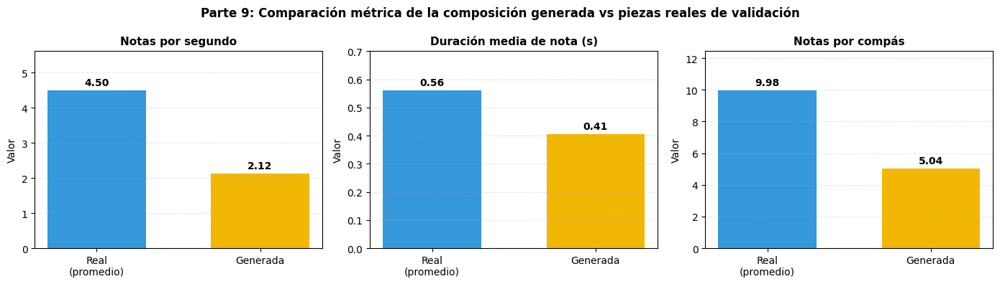


Comparación estadística guardada en 'parte9_evaluacion.png' dentro de results/.
Nota de evaluación auditiva: verificar coherencia armónica y dinámica tímbrica en el audio sintetizado en la Parte 10.

Tabla consolidada de métricas (Modelo LSTM + Evaluación Musical):


,Dimensión,Métrica,Validación / Real,Generada / Train
0,Modelo LSTM,Mejor Época (Early Stopping),3,8 épocas totales
1,Modelo LSTM,Cross-Entropy Loss,1.7945 (Val),1.4208 (Train)
2,Modelo LSTM,Perplejidad (exp(Loss)),6.02 (Val),4.14 (Train)
3,Musical,Pitch Mínimo / Máximo,43.3 / 75.9,41 / 72
4,Musical,Pitch Promedio,60.16,60.88
5,Musical,Notas por segundo,4.50,2.12
6,Musical,Duración media de nota (s),0.56,0.406
7,Musical,Notas por compás,9.98,5.04


In [13]:
# @title Evaluación de la composición generada

def metricas_score(score):
    '''Calcula métricas estructurales de notas, densidad y rango de un objeto Score.'''
    score_sec = score.to("second")
    notas = [n for t in score_sec.tracks for n in t.notes]
    if not notas:
        return {"n_notas": 0, "duracion_s": 0.0, "pitch_min": 0, "pitch_max": 0,
                "pitch_promedio": 0.0, "notas_por_segundo": 0.0,
                "duracion_nota_promedio_s": 0.0, "notas_por_compas": 0.0}
    duracion = float(score_sec.end())
    pitches = [n.pitch for n in notas]
    duraciones = [float(n.duration) for n in notas]
    pulsos = float(score.end()) / float(score.ticks_per_quarter)
    compases = max(1.0, pulsos / 4.0)
    return {
        "n_notas": len(notas),
        "duracion_s": round(duracion, 2),
        "pitch_min": int(min(pitches)),
        "pitch_max": int(max(pitches)),
        "pitch_promedio": round(float(np.mean(pitches)), 2),
        "notas_por_segundo": round(len(notas) / max(duracion, 0.01), 2),
        "duracion_nota_promedio_s": round(float(np.mean(duraciones)), 3),
        "notas_por_compas": round(len(notas) / compases, 2),
    }

metricas_generada = metricas_score(nuevo_score_generado)
print("Métricas de la composición generada:")
print(f"  - Notas: {metricas_generada['n_notas']} | duración: {metricas_generada['duracion_s']}s (~{metricas_generada['duracion_s']/60:.2f} min)")
print(f"  - Rango de pitch: {metricas_generada['pitch_min']}-{metricas_generada['pitch_max']} "
      f"(promedio {metricas_generada['pitch_promedio']})")
print(f"  - Notas por segundo: {metricas_generada['notas_por_segundo']} | "
      f"duración media de nota: {metricas_generada['duracion_nota_promedio_s']}s | "
      f"notas por compás: {metricas_generada['notas_por_compas']}")

# Comparación estadística frente a piezas reales de validación
val_clean_paths = []
for nombre in val_names:
    base = strip_clean_prefix(nombre)
    candidatos = [CLEAN_DIR / nombre, CLEAN_DIR / f"clean_{base}", CLEAN_DIR / f"clean_{nombre}"]
    encontrado = next((c for c in candidatos if c.exists()), None)
    if encontrado:
        val_clean_paths.append(encontrado)

metricas_reales = []
for ruta in val_clean_paths:
    try:
        m = metricas_score(symusic.Score.from_file(str(ruta)))
        if m and m["n_notas"] > 0:
            metricas_reales.append(m)
    except Exception:
        pass

print("\nPromedio del conjunto real de validación:")
for clave in ["pitch_min", "pitch_max", "pitch_promedio", "notas_por_segundo",
              "duracion_nota_promedio_s", "notas_por_compas"]:
    promedio = float(np.mean([m[clave] for m in metricas_reales]))
    print(f"  - {clave}: {promedio:.2f}  (generada: {metricas_generada[clave]})")

# Visualización comparativa: Composición generada vs Conjunto real
claves_grafica = ["notas_por_segundo", "duracion_nota_promedio_s", "notas_por_compas"]
etiquetas = ["Notas por segundo", "Duración media de nota (s)", "Notas por compás"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, clave, etiqueta in zip(axes, claves_grafica, etiquetas):
    reales = [m[clave] for m in metricas_reales]
    val_real_prom = float(np.mean(reales))
    val_gen = metricas_generada[clave]
    barras = ax.bar(["Real\n(promedio)", "Generada"],
                    [val_real_prom, val_gen],
                    color=["#3498db", "#f2b705"], width=0.6)
    ax.set_title(etiqueta, fontsize=11, fontweight="bold")
    ax.set_ylabel("Valor")
    for b in barras:
        h = b.get_height()
        ax.annotate(f"{h:.2f}",
                    xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(val_real_prom, val_gen) * 1.25)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.suptitle("Parte 9: Comparación métrica de la composición generada vs piezas reales de validación",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte9_evaluacion.png", dpi=150)
plt.show()
print("\nComparación estadística guardada en 'parte9_evaluacion.png' dentro de results/.")
print("Nota de evaluación auditiva: verificar coherencia armónica y dinámica tímbrica en el audio sintetizado en la Parte 10.")


# Tabla consolidada de métricas del modelo LSTM y evaluación musical
val_ppl_best = math.exp(float(checkpoint["val_loss"]))
tr_ppl_best = math.exp(float(checkpoint["train_loss"]))
resumen_metricas = pd.DataFrame([
    {"Dimensión": "Modelo LSTM", "Métrica": "Mejor Época (Early Stopping)", "Validación / Real": str(checkpoint["epoch"]), "Generada / Train": f"{len(historial['train_loss'])} épocas totales"},
    {"Dimensión": "Modelo LSTM", "Métrica": "Cross-Entropy Loss", "Validación / Real": f"{float(checkpoint['val_loss']):.4f} (Val)", "Generada / Train": f"{float(checkpoint['train_loss']):.4f} (Train)"},
    {"Dimensión": "Modelo LSTM", "Métrica": "Perplejidad (exp(Loss))", "Validación / Real": f"{val_ppl_best:.2f} (Val)", "Generada / Train": f"{tr_ppl_best:.2f} (Train)"},
    {"Dimensión": "Musical", "Métrica": "Pitch Mínimo / Máximo", "Validación / Real": f"{np.mean([m['pitch_min'] for m in metricas_reales]):.1f} / {np.mean([m['pitch_max'] for m in metricas_reales]):.1f}", "Generada / Train": f"{metricas_generada['pitch_min']} / {metricas_generada['pitch_max']}"},
    {"Dimensión": "Musical", "Métrica": "Pitch Promedio", "Validación / Real": f"{np.mean([m['pitch_promedio'] for m in metricas_reales]):.2f}", "Generada / Train": f"{metricas_generada['pitch_promedio']:.2f}"},
    {"Dimensión": "Musical", "Métrica": "Notas por segundo", "Validación / Real": f"{np.mean([m['notas_por_segundo'] for m in metricas_reales]):.2f}", "Generada / Train": f"{metricas_generada['notas_por_segundo']:.2f}"},
    {"Dimensión": "Musical", "Métrica": "Duración media de nota (s)", "Validación / Real": f"{np.mean([m['duracion_nota_promedio_s'] for m in metricas_reales]):.2f}", "Generada / Train": f"{metricas_generada['duracion_nota_promedio_s']:.3f}"},
    {"Dimensión": "Musical", "Métrica": "Notas por compás", "Validación / Real": f"{np.mean([m['notas_por_compas'] for m in metricas_reales]):.2f}", "Generada / Train": f"{metricas_generada['notas_por_compas']:.2f}"},
])
print("\nTabla consolidada de métricas (Modelo LSTM + Evaluación Musical):")
display(resumen_metricas)


## Parte 10. Síntesis y exportación de audio

Síntesis de audio acústico en formato WAV de 16 bits a 22,050 Hz implementada en NumPy y Python puro, sin requerir dependencias externas complejas ni SoundFonts:
- Osciladores sinusoidales aditivos con sobretonos armónicos para enriquecer el timbre.
- Envolvente exponencial ADSR (*Attack, Decay, Sustain, Release*) para emular la dinámica acústica instrumental de un piano.

In [14]:
# @title Síntesis y exportación de audio

def sintetizar_audio_midi(score, ruta_wav_salida, sample_rate=22050):
    '''Sintetiza audio en formato WAV a partir de un objeto Score mediante síntesis aditiva y envolvente ADSR.'''
    duracion_sec = float(score.to("second").end()) + 1.0
    total_muestras = int(math.ceil(duracion_sec * sample_rate))
    buffer = np.zeros(total_muestras, dtype=np.float32)

    score_sec = score.to("second")
    for track in score_sec.tracks:
        for note in track.notes:
            frecuencia = 440.0 * (2.0 ** ((note.pitch - 69) / 12.0))
            inicio = float(note.time)
            duracion = max(float(note.duration), 0.05)
            idx_inicio = int(inicio * sample_rate)
            n_muestras = int(duracion * sample_rate)
            if idx_inicio >= total_muestras:
                continue
            if idx_inicio + n_muestras > total_muestras:
                n_muestras = total_muestras - idx_inicio

            t = np.arange(n_muestras) / sample_rate
            # Envolvente exponencial suave: ataque rápido y decaimiento armónico
            ataque = np.minimum(t / 0.01, 1.0)
            decaimiento = np.exp(-t / max(duracion * 0.7, 0.1))
            envolvente = ataque * decaimiento
            # Superposición de armónicos para enriquecer el contenido espectral
            onda = np.sin(2.0 * np.pi * frecuencia * t) + 0.3 * np.sin(4.0 * np.pi * frecuencia * t)
            amplitud = (note.velocity / 127.0) * envolvente
            buffer[idx_inicio: idx_inicio + n_muestras] += (onda * amplitud).astype(np.float32)

    # Normalización de amplitud para prevenir distorsión (clipping)
    maximo = np.max(np.abs(buffer))
    if maximo > 0:
        buffer = buffer / maximo * 0.95
    buffer_int16 = (buffer * 32767.0).astype(np.int16)

    with wave.open(str(ruta_wav_salida), "w") as wav_file:
        wav_file.setnchannels(1)
        wav_file.setsampwidth(2)
        wav_file.setframerate(sample_rate)
        wav_file.writeframes(buffer_int16.tobytes())


ruta_wav = RESULTS_DIR / "mi_primera_composicion_ia_remi.wav"
sintetizar_audio_midi(nuevo_score_generado, ruta_wav)
print(f"[AUDIO] Archivo de audio WAV generado en: {ruta_wav}")
display(Audio(str(ruta_wav)))


[AUDIO] Archivo de audio WAV generado en: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/mi_primera_composicion_ia_remi.wav


## Parte 11. Interfaz Interactiva, Piano Roll y Reproductores Visuales Animados

Suite completa de visualización, reproducción e interacción con el modelo **DeepMidi-LSTM**:
1. **Piano Roll:** Dispersión temporal de notas sobre el eje de alturas MIDI (21 a 108) con codificación por color de la velocidad dinámica.
2. **Partitura Interactiva Adaptativa (`abcjs` + Web Audio API):** Renderizado del pentagrama con iluminación dinámica sincronizada, controles de reproducción (*Reproducir*, *Inicio*) y barra de progreso (*seek*).
3. **Visualizador de Notas Cayendo (*Synthesia* en HTML5 Canvas + Web Audio API):** Animación en tiempo real donde la posición horizontal codifica la altura tonal, la caída representa el tiempo y el sonido se dispara exactamente al cruzar la línea dorada.
4. **Panel Interactivo de Generación y Reproductor (`ipywidgets`):** Interfaz gráfica dentro del cuaderno que permite al usuario modificar en tiempo real la *Temperatura*, *Top-K*, *Repetition Penalty*, longitud de secuencia y pieza semilla para generar y escuchar nuevas composiciones con un clic.

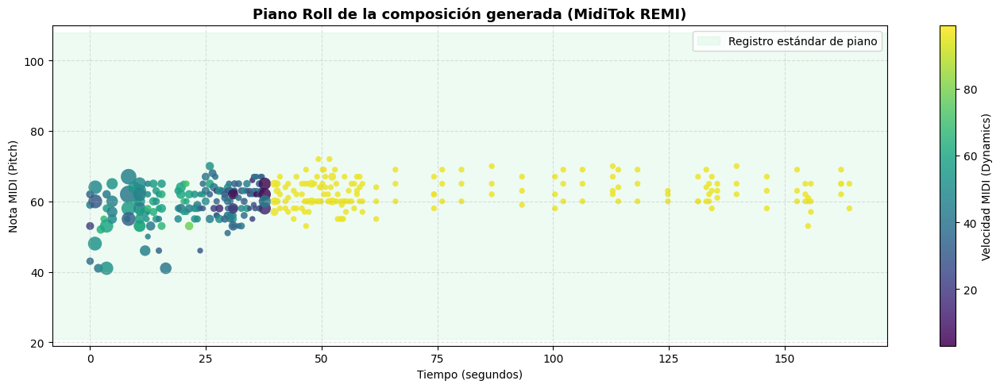

Piano roll exportado a 'parte10_piano_roll_generada.png' dentro de results/.


In [15]:
# @title Piano roll de la composición generada

def plot_piano_roll_from_score(score, titulo="Piano Roll - Composición generada por IA"):
    '''Genera y almacena el piano roll de un objeto Score (tiempo vs altura tonal).'''
    plt.figure(figsize=(14, 5))
    score_sec = score.to("second")
    pistas_notas = 0
    for t in score_sec.tracks:
        if not t.notes:
            continue
        pistas_notas += 1
        starts = [float(n.time) for n in t.notes]
        durations = [float(n.duration) for n in t.notes]
        pitches = [n.pitch for n in t.notes]
        velocities = [n.velocity for n in t.notes]
        p = plt.scatter(starts, pitches, c=velocities, cmap="viridis",
                        s=np.array(durations) * 80 + 10, alpha=0.85, edgecolors="none")
    plt.title(titulo, fontsize=13, fontweight="bold")
    plt.xlabel("Tiempo (segundos)")
    plt.ylabel("Nota MIDI (Pitch)")
    plt.ylim(MIN_PITCH - 2, MAX_PITCH + 2)
    plt.axhspan(MIN_PITCH, MAX_PITCH, color="#2ecc71", alpha=0.08, label="Registro estándar de piano")
    plt.grid(True, linestyle="--", alpha=0.4)
    if pistas_notas > 0:
        cbar = plt.colorbar(p)
        cbar.set_label("Velocidad MIDI (Dynamics)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "parte10_piano_roll_generada.png", dpi=150)
    plt.show()


plot_piano_roll_from_score(nuevo_score_generado,
                           "Piano Roll de la composición generada (MidiTok REMI)")
print("Piano roll exportado a 'parte10_piano_roll_generada.png' dentro de results/.")


In [16]:
#  @title Partitura animada interactiva

import json
import base64
import html
from IPython.display import HTML, display


def score_to_abc(score):
    '''Convierte un objeto Score de symusic a notación ABC estándar.'''
    pitches_map = {
        60: "C", 61: "^C", 62: "D", 63: "^D", 64: "E", 65: "F", 66: "^F",
        67: "G", 68: "^G", 69: "A", 70: "^A", 71: "B",
        72: "c", 73: "^c", 74: "d", 75: "^d", 76: "e", 77: "f", 78: "^f",
        79: "g", 80: "^g", 81: "a", 82: "^a", 83: "b",
        84: "c'", 85: "^c'", 86: "d'", 87: "^d'", 88: "e'", 89: "f'",
    }
    notas = sorted([n for t in score.tracks for n in t.notes], key=lambda x: x.time)
    if not notas:
        return "C4"
    ticks_per_quarter = float(score.ticks_per_quarter)
    abc_tokens = []
    compas_ticks = 0
    ticks_per_bar = ticks_per_quarter * 4

    for n in notas:
        p = n.pitch
        while p < 48: p += 12
        while p > 89: p -= 12
        simb = pitches_map.get(p, "c")
        dur_cuartos = max(0.25, round((n.duration / ticks_per_quarter) * 4) / 4)
        if dur_cuartos == 1.0:
            dur_str = ""
        elif dur_cuartos == 0.5:
            dur_str = "/2"
        elif dur_cuartos == 0.25:
            dur_str = "/4"
        elif dur_cuartos == 2.0:
            dur_str = "2"
        elif dur_cuartos == 4.0:
            dur_str = "4"
        else:
            dur_str = f"{int(dur_cuartos*4)}/4"

        abc_tokens.append(f"{simb}{dur_str}")
        compas_ticks += n.duration
        if compas_ticks >= ticks_per_bar:
            abc_tokens.append("|")
            compas_ticks = 0

    return " ".join(abc_tokens)


def player_page(wav_bytes, abc_notation, title):
    '''Crea una interfaz web responsiva donde la partitura se adapta al ancho de pantalla e ilumina notas sincronizadas.'''
    encoded = base64.b64encode(wav_bytes).decode()


    page = r'''<!doctype html>
<html>
<head>
<meta charset="utf-8">
<!-- Cargamos abcjs para renderizar la partitura -->
<script src="https://cdnjs.cloudflare.com/ajax/libs/abcjs/6.2.2/abcjs-basic-min.js" type="text/javascript"></script>
<style>
body {
    margin: 0;
    padding: 10px;
    background: #101724;
    color: #eaf1ff;
    font: 14px system-ui;
}
.panel {
    padding: 15px;
    background: #182235;
    border: 1px solid #344052;
    border-radius: 16px;
}
h3 {
    margin: 0 0 10px;
    font-size: 17px;
}
.controls {
    display: flex;
    gap: 10px;
    align-items: center;
    flex-wrap: wrap;
    margin-bottom: 14px;
}
button {
    background: #263e61;
    color: white;
    border: 1px solid #50658a;
    border-radius: 10px;
    padding: 10px 14px;
    cursor: pointer;
    font-weight: bold;
}
button:hover {
    background: #365b88;
}
#seek {
    flex: 1;
    min-width: 140px;
    accent-color: #60b5ff;
}
/* Contenedor con barra de desplazamiento horizontal para modo corrido tipo vídeo */
#paper-container {
    width: 100%;
    overflow-x: auto;
    background: white;
    border-radius: 12px;
    padding: 15px 10px;
    box-sizing: border-box;
}
#paper {
    min-width: 3200px; /* Forzar el diseño extendido horizontalmente para toda la melodía */
}
#msg {
    color: #9ec7ea;
    font-size: 12px;
    margin-top: 10px;
}

/* Todo el resto de elementos y notas inactivas en negro absoluto */
#paper svg path,
#paper svg ellipse,
#paper svg rect,
#paper svg text {
    fill: #000000 !important;
    stroke: #000000 !important;
}

/* Excepto el fondo de la hoja */
#paper svg {
    background: transparent;
}
</style>
</head>

<body>
<div class="panel">
    <h3 id="title"></h3>

    <div class="controls">
        <button id="play">▖ Reproducir</button>
        <button id="reset">ℑ Inicio</button>
        <span id="time">0:00 / 0:00</span>
        <input id="seek" type="range" min="0" max="1000" value="0">
    </div>

    <div id="paper-container">
        <div id="paper"></div>
    </div>
    <div id="msg"></div>
</div>

<script>
const WAV = '__WAV__';
const ABC_DATA = `__ABC_DATA__`;
const TITLE = __TITLE__;

const $ = id => document.getElementById(id);
$('title').textContent = TITLE;

let ctx, buffer, source = null;
let started = 0, offset = 0, playing = false, duration = 0;
let tuneObj = null;

// Renderizar la partitura con ABCJS con escala grande para que se vea a lo alto
function renderScore() {
    // Forzar todo en una sola línea continua deshabilitando el salto automático de página de abcjs
    const abcString = "X:1\nT:" + TITLE + "\nM:4/4\nL:1/4\nK:C\n%%wrapwidth 50000\n" + ABC_DATA;
    tuneObj = ABCJS.renderAbc("paper", abcString, {
        responsive: "none", // No redimensionar para que mantenga el desplazamiento horizontal
        scale: 1.1, // Tamaño grande del pentagrama a lo alto de la ventana
        add_classes: true
    })[0];
}

const fmt = t => {
    t = Math.max(0, Math.floor(t));
    return Math.floor(t / 60) + ':' + String(t % 60).padStart(2, '0');
};

const position = () =>
    playing ? Math.min(duration, offset + ctx.currentTime - started) : offset;

function update() {
    const p = position();
    $('time').textContent = fmt(p) + ' / ' + fmt(duration);
    $('seek').value = duration ? Math.round(p / duration * 1000) : 0;

    if (tuneObj && duration > 0) {
        const pct = p / duration;

        // Seleccionamos los grupos de notas (elementos con clase abcjs-note)
        const noteGroups = document.querySelectorAll("#paper svg g.abcjs-note");

        if (noteGroups.length > 0) {
            const targetIndex = Math.floor(pct * noteGroups.length);
            let targetElement = null;

            noteGroups.forEach((group, index) => {
                const elements = group.querySelectorAll("path, ellipse, rect");
                if (index === targetIndex) {
                    // Iluminar todo el cuerpo de la nota actual (cabeza y plica) en rojo
                    elements.forEach(el => {
                        el.style.setProperty('fill', '#ff3b30', 'important');
                        el.style.setProperty('stroke', '#ff3b30', 'important');
                    });
                    targetElement = group;
                } else {
                    // Restablecer en negro absoluto las notas inactivas
                    elements.forEach(el => {
                        el.style.setProperty('fill', '#000000', 'important');
                        el.style.setProperty('stroke', '#000000', 'important');
                    });
                }
            });

            // Desplazamiento automático para centrar la nota iluminada
            if (targetElement) {
                const container = $('paper-container');
                const elLeft = targetElement.getBoundingClientRect().left + container.scrollLeft - container.getBoundingClientRect().left;
                container.scrollTo({
                    left: elLeft - (container.clientWidth / 2),
                    behavior: 'smooth'
                });
            }
        } else {
            // Fallback si no hay clases detalladas: iluminamos el conjunto SVG básico secuencialmente
            const elements = document.querySelectorAll("#paper svg path, #paper svg ellipse, #paper svg rect");
            if (elements.length > 0) {
                const targetIndex = Math.floor(pct * elements.length);
                let targetElement = null;
                elements.forEach((el, index) => {
                    if (index === targetIndex) {
                        el.style.setProperty('fill', '#ff3b30', 'important');
                        el.style.setProperty('stroke', '#ff3b30', 'important');
                        targetElement = el;
                    } else {
                        el.style.setProperty('fill', '#000000', 'important');
                        el.style.setProperty('stroke', '#000000', 'important');
                    }
                });
                if (targetElement) {
                    const container = $('paper-container');
                    const elLeft = targetElement.getBoundingClientRect().left + container.scrollLeft - container.getBoundingClientRect().left;
                    container.scrollTo({
                        left: elLeft - (container.clientWidth / 2),
                        behavior: 'smooth'
                    });
                }
            }
        }
    }
}

async function init() {
    try {
        ctx = new (window.AudioContext || window.webkitAudioContext)();

        const bin = atob(WAV);
        const bytes = new Uint8Array(bin.length);

        for (let i = 0; i < bin.length; i++)
            bytes[i] = bin.charCodeAt(i);

        buffer = await ctx.decodeAudioData(bytes.buffer.slice(0));
        duration = buffer.duration;

        renderScore();
        update();

    } catch (e) {
        $('msg').textContent = 'Error: ' + e.message;
    }
}

function pause(keep = true) {
    if (playing) {
        let p = position();
        source.onended = null;
        try { source.stop(); } catch (e) {}
        source.disconnect();
        playing = false;
        source = null;
        if (keep) offset = p;
    }
    $('play').textContent = '▖ Reproducir';
    update();
}

async function play() {
    if (!buffer) return;
    await ctx.resume();
    if (playing) {
        pause();
        return;
    }
    if (offset >= duration - 0.01) offset = 0;

    source = ctx.createBufferSource();
    source.buffer = buffer;
    source.connect(ctx.destination);
    started = ctx.currentTime;

    source.onended = () => {
        if (playing) {
            pause(false);
            offset = duration;
            update();
        }
    };

    source.start(0, offset);
    playing = true;
    $('play').textContent = '⏸ Pausar';
}

$('play').onclick = play;
$('reset').onclick = () => {
    let was = playing;
    pause();
    offset = 0;
    was ? play() : update();
};
$('seek').oninput = e => {
    let was = playing;
    pause();
    offset = Number(e.target.value) / 1000 * duration;
    was ? play() : update();
};

function draw() {
    update();
    requestAnimationFrame(draw);
}

init();
draw();
</script>
</body>
</html>'''

    page = page.replace('__WAV__', encoded)
    page = page.replace('__ABC_DATA__', abc_notation)
    page = page.replace('__TITLE__', json.dumps(title))

    # Guardar página completa independiente para abrir fuera de Colab
    ruta_html = RESULTS_DIR / "partitura_composicion_generada.html"
    ruta_html.write_text(page, encoding="utf-8")
    print(f"Reproductor interactivo guardado en: {ruta_html}")

    return f'<iframe style="width:100%;height:520px;border:0" allow="autoplay" srcdoc="{html.escape(page, quote=True)}"></iframe>'


# Generación del reproductor de partitura con audio sincronizado
abc_data = score_to_abc(nuevo_score_generado)
iframe_html = player_page(
    wav_bytes=ruta_wav.read_bytes(),
    abc_notation=abc_data,
    title="Composición Generada por IA (Red LSTM)"
)
display(HTML(iframe_html))


Reproductor interactivo guardado en: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/partitura_composicion_generada.html


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [17]:
# @title Animacion notas cayendo

def construir_animacion_notas(score, titulo):
    score_sec = score.to("second")
    notas = []
    for track in score_sec.tracks:
        for n in track.notes:
            inicio = float(n.time)
            fin = inicio + float(n.duration)
            notas.append({"s": round(inicio, 3), "e": round(fin, 3),
                          "p": int(n.pitch), "v": int(n.velocity)})
    notas.sort(key=lambda d: d["s"])
    if not notas:
        print("[ANIMACIÓN] No se detectaron notas en la composición generada para animar.")
        return None
    duracion = max(n["e"] for n in notas)
    datos_js = "const SONGS = " + json.dumps(
        {"generada": {"notes": notas, "duration": duracion}}, ensure_ascii=False) + ";"
    plantilla = r'''<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITULO__</title>
<style>
  body { margin: 0; background: #0f1420; color: #e8ecf3; font-family: system-ui, sans-serif; }
  .wrap { max-width: 1100px; margin: 0 auto; padding: 16px; }
  h1 { font-size: 20px; margin: 4px 0 2px; }
  p.sub { color: #9fb0c8; margin: 0 0 12px; font-size: 14px; }
  .controls { display: flex; flex-wrap: wrap; gap: 8px; align-items: center; margin-bottom: 10px; }
  button, select { background: #1d2a44; color: #e8ecf3; border: 1px solid #3a4a63;
    border-radius: 8px; padding: 8px 14px; font-size: 15px; cursor: pointer; }
  button.primary { background: #f2b705; color: #231a00; border-color: #f2b705; font-weight: 700; }
  button.active { outline: 2px solid #f2b705; }
  input[type=range] { flex: 1; min-width: 160px; accent-color: #f2b705; }
  .time { font-variant-numeric: tabular-nums; color: #9fb0c8; font-size: 14px; }
  .now-note { display: flex; align-items: baseline; gap: 12px; background: #16213a;
    border: 1px solid #3a4a63; border-radius: 10px; padding: 10px 14px; margin-bottom: 10px; }
  .now-note .label { color: #9fb0c8; font-size: 13px; text-transform: uppercase; letter-spacing: .08em; }
  .now-note .note { font-size: 34px; font-weight: 800; color: #f2b705; min-width: 120px; }
  .now-note .freq { color: #9fb0c8; font-size: 14px; }
  canvas { width: 100%; height: 560px; display: block; background: #0b101c;
    border: 1px solid #26324a; border-radius: 12px; }
  .legend { display: flex; gap: 18px; flex-wrap: wrap; margin: 10px 0; font-size: 13px; color: #c6d2e4; }
  .dot { display: inline-block; width: 12px; height: 12px; border-radius: 3px; margin-right: 6px; vertical-align: -1px; }
  .howto { background: #131c2e; border: 1px solid #26324a; border-radius: 12px; padding: 14px 18px; font-size: 14px; line-height: 1.6; }
  .howto h2 { font-size: 16px; margin: 0 0 6px; }
  .howto li { margin-bottom: 6px; }
</style>
</head>
<body>
<div class="wrap">
  <h1>__TITULO__</h1>
  <p class="sub">Mi composición generada por el LSTM, con las notas cayendo en el pentagrama. La nota que suena es siempre la que cruza la línea dorada.</p>

  <div class="controls">
    <button id="btnGenerada" class="active">Mi composición generada</button>
    <button id="btnPlay" class="primary">▶ Reproducir</button>
    <button id="btnRestart">↺ Reiniciar</button>
    <select id="selSpeed">
      <option value="0.5">0.5× lento</option>
      <option value="1" selected>1× normal</option>
      <option value="1.5">1.5× rápido</option>
    </select>
    <input id="seek" type="range" min="0" max="100" step="0.1" value="0">
    <span class="time" id="timeLabel">0:00 / 0:00</span>
  </div>

  <div class="now-note">
    <span class="label">Nota sonando</span>
    <span class="note" id="nowNote">—</span>
    <span class="freq" id="nowFreq"></span>
  </div>

  <canvas id="stage"></canvas>

  <div class="legend">
    <span><span class="dot" style="background:#6f8fb5"></span>Nota futura (aún no suena)</span>
    <span><span class="dot" style="background:#f2b705"></span>Nota sonando ahora</span>
    <span><span class="dot" style="background:#556070"></span>Nota pasada (se desvanece)</span>
  </div>

  <div class="howto">
    <h2>Cómo funciona esta animación</h2>
    <ol>
      <li><b>La altura de la nota es su posición horizontal.</b> Cada nota cae por la columna de su altura en el pentagrama: a la derecha las agudas, a la izquierda las graves. Las cinco líneas gruesas son las del pentagrama de sol (Mi, Sol, Si, Re, Fa).</li>
      <li><b>El tiempo es la caída.</b> Las notas bajan a velocidad constante y el largo de cada barra es su duración: una nota larga es una barra larga.</li>
      <li><b>Solo suena lo que cruza la línea dorada «AHORA».</b> La nota se ilumina en dorado, se escribe su nombre (Do, Re, Mi…) y suena justo cuando su cabeza toca la línea. Las futuras se ven tenues arriba y las pasadas se desvanecen abajo, así nunca se confunden.</li>
      <li><b>El sonido sale de Web Audio:</b> cada nota es un oscilador con la frecuencia de su MIDI (440 × 2^((m−69)/12)) y una envolvente de ataque y caída, sin archivos de audio.</li>
    </ol>
  </div>
</div>

<script>
__DATA__

const NAMES = ["Do","Do#","Re","Re#","Mi","Fa","Fa#","Sol","Sol#","La","La#","Si"];
function noteName(m) { return NAMES[m % 12] + (Math.floor(m / 12) - 1); }
function freq(m) { return 440 * Math.pow(2, (m - 69) / 12); }
function fmt(t) { const m = Math.floor(t / 60), s = Math.floor(t % 60); return m + ":" + String(s).padStart(2, "0"); }

const canvas = document.getElementById("stage");
const ctx = canvas.getContext("2d");
const btnPlay = document.getElementById("btnPlay");
const btnRestart = document.getElementById("btnRestart");
const seek = document.getElementById("seek");
const timeLabel = document.getElementById("timeLabel");
const nowNoteEl = document.getElementById("nowNote");
const nowFreqEl = document.getElementById("nowFreq");
const selSpeed = document.getElementById("selSpeed");

let notes = SONGS["generada"].notes;
let duration = SONGS["generada"].duration;
let lo = Math.min(...notes.map(n => n.p)) - 2;
let hi = Math.max(...notes.map(n => n.p)) + 2;

let playing = false;
let speed = 1;
let baseTime = 0;
let baseCtxTime = 0;
let audioCtx = null;
let nextIdx = 0;
let activeSources = [];
const FALL_PX_PER_SEC = 130;

function songTime() {
  if (!playing || !audioCtx) return baseTime;
  return Math.min(duration, baseTime + (audioCtx.currentTime - baseCtxTime) * speed);
}

function xOf(pitch, W) {
  const margin = 46;
  return margin + (pitch - lo) / (hi - lo) * (W - 2 * margin);
}
function yOf(t, nowY, tNow) { return nowY - (t - tNow) * FALL_PX_PER_SEC; }

function ensureAudio() {
  if (!audioCtx) audioCtx = new (window.AudioContext || window.webkitAudioContext)();
  if (audioCtx.state === "suspended") audioCtx.resume();
}

function stopSources() {
  for (const s of activeSources) { try { s.stop(); } catch (e) {} }
  activeSources = [];
}

function scheduleFrom(t) {
  let a = 0, b = notes.length;
  while (a < b) { const m = (a + b) >> 1; if (notes[m].s < t) a = m + 1; else b = m; }
  nextIdx = a;
}

function scheduleAhead() {
  if (!playing || !audioCtx) return;
  const t = songTime();
  const horizon = t + 0.4;
  while (nextIdx < notes.length && notes[nextIdx].s < horizon) {
    const n = notes[nextIdx];
    const when = baseCtxTime + Math.max(0, (n.s - baseTime) / speed);
    const dur = Math.max(0.05, (n.e - n.s) / speed);
    const osc = audioCtx.createOscillator();
    const g = audioCtx.createGain();
    osc.type = "triangle";
    osc.frequency.value = freq(n.p);
    const peak = 0.28 * (n.v / 127);
    g.gain.setValueAtTime(0.0001, when);
    g.gain.linearRampToValueAtTime(peak, when + 0.02);
    g.gain.exponentialRampToValueAtTime(0.0001, when + dur + 0.12);
    osc.connect(g); g.connect(audioCtx.destination);
    osc.start(when); osc.stop(when + dur + 0.2);
    activeSources.push(osc);
    nextIdx++;
  }
}
setInterval(scheduleAhead, 60);

function play() {
  ensureAudio();
  baseTime = songTime();
  baseCtxTime = audioCtx.currentTime;
  scheduleFrom(baseTime);
  playing = true;
  btnPlay.textContent = "⏸ Pausar";
}
function pause() {
  baseTime = songTime();
  playing = false;
  stopSources();
  btnPlay.textContent = "▶ Reproducir";
}
btnPlay.onclick = () => { playing ? pause() : play(); };
btnRestart.onclick = () => { pause(); baseTime = 0; seek.value = 0; };
document.getElementById("btnGenerada").onclick = () => { pause(); baseTime = 0; seek.value = 0; };
selSpeed.onchange = () => {
  const wasPlaying = playing;
  if (wasPlaying) pause();
  speed = parseFloat(selSpeed.value);
  if (wasPlaying) play();
};
seek.oninput = () => {
  const wasPlaying = playing;
  if (wasPlaying) pause();
  baseTime = parseFloat(seek.value);
  if (wasPlaying) play();
};

function resize() {
  const dpr = window.devicePixelRatio || 1;
  const r = canvas.getBoundingClientRect();
  canvas.width = Math.round(r.width * dpr);
  canvas.height = Math.round(r.height * dpr);
  ctx.setTransform(dpr, 0, 0, dpr, 0, 0);
}
window.addEventListener("resize", resize);
resize();

const STAFF_LINES = [64, 67, 71, 74, 77, 43, 47, 50, 53, 57];

function draw() {
  const W = canvas.getBoundingClientRect().width;
  const H = canvas.getBoundingClientRect().height;
  const t = songTime();
  const nowY = H - 90;
  ctx.clearRect(0, 0, W, H);

  for (let p = lo; p <= hi; p++) {
    const x = xOf(p, W);
    if (STAFF_LINES.includes(p)) {
      ctx.strokeStyle = "#3a4a63"; ctx.lineWidth = 2;
    } else if (p % 12 === 0) {
      ctx.strokeStyle = "#232f47"; ctx.lineWidth = 1;
    } else { continue; }
    ctx.beginPath(); ctx.moveTo(x, 8); ctx.lineTo(x, H - 8); ctx.stroke();
  }
  ctx.fillStyle = "#7d8ea8"; ctx.font = "11px system-ui"; ctx.textAlign = "center";
  for (let p = lo; p <= hi; p++) {
    if (p % 12 === 0) ctx.fillText(noteName(p), xOf(p, W), 22);
  }
  ctx.fillStyle = "#7d8ea8"; ctx.textAlign = "left";
  ctx.fillText("← graves", 8, H - 14);
  ctx.textAlign = "right";
  ctx.fillText("agudas →", W - 8, H - 14);

  ctx.strokeStyle = "#f2b705"; ctx.lineWidth = 3;
  ctx.beginPath(); ctx.moveTo(0, nowY); ctx.lineTo(W, nowY); ctx.stroke();
  ctx.fillStyle = "#f2b705"; ctx.font = "bold 13px system-ui"; ctx.textAlign = "left";
  ctx.fillText("AHORA — aquí suena la nota", 10, nowY - 8);

  let sounding = null;
  for (const n of notes) {
    if (n.s > t + 8) break;
    if (n.e < t - 1) continue;
    const x = xOf(n.p, W);
    const yTop = yOf(n.e, nowY, t);
    const yBot = yOf(n.s, nowY, t);
    let color, alpha;
    if (t >= n.s && t < n.e) {
      color = "#f2b705"; alpha = 1;
      if (!sounding || n.s > sounding.s) sounding = n;
    } else if (n.s > t) {
      color = "#6f8fb5"; alpha = 0.35;
    } else {
      color = "#556070"; alpha = Math.max(0, 0.45 * (1 - (t - n.e) / 0.6));
    }
    if (alpha <= 0.01) continue;
    ctx.globalAlpha = alpha;
    if (t >= n.s && t < n.e) { ctx.shadowColor = "#f2b705"; ctx.shadowBlur = 14; }
    ctx.fillStyle = color;
    const bw = 16;
    const top = Math.min(yTop, yBot), h = Math.max(10, Math.abs(yBot - yTop));
    ctx.beginPath();
    ctx.roundRect(x - bw / 2, top, bw, h, 5);
    ctx.fill();
    ctx.shadowBlur = 0;
    ctx.beginPath();
    ctx.ellipse(x, yBot, 10, 6.5, -0.25, 0, Math.PI * 2);
    ctx.fill();
    ctx.globalAlpha = 1;
    if (t >= n.s && t < n.e) {
      ctx.fillStyle = "#ffe9a8"; ctx.font = "bold 13px system-ui"; ctx.textAlign = "left";
      ctx.fillText(noteName(n.p), x + 14, yBot + 4);
    }
  }

  if (sounding) {
    nowNoteEl.textContent = noteName(sounding.p);
    nowFreqEl.textContent = freq(sounding.p).toFixed(1) + " Hz · MIDI " + sounding.p;
  } else {
    nowNoteEl.textContent = "—";
    nowFreqEl.textContent = "";
  }

  if (document.activeElement !== seek) seek.value = t;
  timeLabel.textContent = fmt(t) + " / " + fmt(duration);
  if (playing && t >= duration) pause();

  requestAnimationFrame(draw);
}
seek.max = duration;
requestAnimationFrame(draw);
</script>
</body>
</html>
'''
    html = plantilla.replace("__DATA__", datos_js).replace("__TITULO__", titulo)
    return html


html_animacion = construir_animacion_notas(
    nuevo_score_generado, "DeepMidi-LSTM — Visualizador de notas cayendo en pentagrama")
if html_animacion:
    ruta_html = RESULTS_DIR / "animacion_composicion_generada.html"
    ruta_html.write_text(html_animacion, encoding="utf-8")
    print(f"[ANIMACIÓN] Visualizador interactivo guardado en {ruta_html} "
          f"({len(html_animacion)} caracteres, también se puede abrir en el navegador).")
    display(HTML(html_animacion))

[ANIMACIÓN] Visualizador interactivo guardado en /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/animacion_composicion_generada.html (27269 caracteres, también se puede abrir en el navegador).


In [18]:
# @title Interfaz Interactiva de Generación y Reproductor (Panel de Control DeepMidi-LSTM)

try:
    import ipywidgets as widgets
    from IPython.display import clear_output

    opciones_semilla = [(f"{i}: {nombre}", i) for i, nombre in enumerate(val_names[:20])]

    w_semilla = widgets.Dropdown(
        options=opciones_semilla,
        value=min(1, len(opciones_semilla) - 1),
        description="Semilla:",
        style={"description_width": "130px"},
        layout=widgets.Layout(width="440px"),
    )
    w_temp = widgets.FloatSlider(
        value=HIPERPARAMETROS["temperatura"], min=0.30, max=1.30, step=0.02,
        description="Temperatura (T):",
        style={"description_width": "130px"},
        layout=widgets.Layout(width="440px"),
    )
    w_topk = widgets.IntSlider(
        value=HIPERPARAMETROS["top_k"], min=5, max=50, step=1,
        description="Top-K:",
        style={"description_width": "130px"},
        layout=widgets.Layout(width="440px"),
    )
    w_rep = widgets.FloatSlider(
        value=HIPERPARAMETROS["repetition_penalty"], min=1.00, max=1.50, step=0.02,
        description="Rep. Penalty (α):",
        style={"description_width": "130px"},
        layout=widgets.Layout(width="440px"),
    )
    w_pasos = widgets.IntSlider(
        value=600, min=200, max=1500, step=100,
        description="Pasos (tokens):",
        style={"description_width": "130px"},
        layout=widgets.Layout(width="440px"),
    )
    btn_generar = widgets.Button(
        description="🎼 Generar y Reproducir Composición",
        button_style="primary",
        layout=widgets.Layout(width="300px", height="38px"),
    )
    salida_panel = widgets.Output()

    def on_generar_click(_):
        with salida_panel:
            clear_output(wait=True)
            idx_s = w_semilla.value
            seq_ref = val_seqs[idx_s]
            fp_idx = next((i for i, t in enumerate(seq_ref) if "Pitch_" in tokenizer[t]), 0)
            b_idx = max(0, fp_idx - 1)
            while b_idx > 0 and "Bar_" not in tokenizer[seq_ref[b_idx]]:
                b_idx -= 1
            sem = list(seq_ref[b_idx: b_idx + 32])

            print(f"[LSTM] Generando {w_pasos.value} tokens | T={w_temp.value:.2f} | "
                  f"Top-K={w_topk.value} | α={w_rep.value:.2f} | Semilla='{val_names[idx_s]}'...")
            toks = generar_musica_tokens(
                modelo=modelo,
                semilla_ids=sem,
                pasos_a_generar=w_pasos.value,
                temperatura=w_temp.value,
                top_k=w_topk.value,
                repetition_penalty=w_rep.value,
                ventana_repeticion=HIPERPARAMETROS["ventana_repeticion"],
                pad_id=pad_id,
            )
            sc = tokenizer.decode([toks])
            m_tick = min((n.time for t in sc.tracks for n in t.notes), default=0)
            if m_tick > 0:
                for t in sc.tracks:
                    for n in t.notes:
                        n.time -= m_tick

            ruta_mid_ui = RESULTS_DIR / "composicion_interfaz_lstm.mid"
            ruta_wav_ui = RESULTS_DIR / "composicion_interfaz_lstm.wav"
            sc.dump_midi(str(ruta_mid_ui))
            sintetizar_audio_midi(sc, ruta_wav_ui)
            m_ui = metricas_score(sc)
            print(f"[OK] {m_ui['n_notas']} notas | {m_ui['duracion_s']}s | "
                  f"Pitch: {m_ui['pitch_min']}-{m_ui['pitch_max']} | "
                  f"Notas/s: {m_ui['notas_por_segundo']}")
            display(Audio(str(ruta_wav_ui)))

    btn_generar.on_click(on_generar_click)

    encabezado_ui = widgets.HTML(
        "<h3 style='margin:0 0 8px; color:#1f4e79;'>🎛️ Panel de Control Interactivo — DeepMidi-LSTM</h3>"
        "<p style='margin:0 0 10px; font-size:13px; color:#555;'>"
        "Modifique los hiperparámetros de muestreo estocástico de la red LSTM para sintetizar y reproducir nuevas piezas.</p>"
    )
    panel_ui = widgets.VBox([encabezado_ui, w_semilla, w_temp, w_topk, w_rep, w_pasos, btn_generar, salida_panel])
    print("[INTERFAZ] Panel de Control Interactivo DeepMidi-LSTM inicializado.")
    print("Ajuste los hiperparámetros de inferencia (Temperatura, Top-K, Repetition Penalty, Pasos) y presione 'Generar y Reproducir' para crear una nueva composición en vivo.")
    display(panel_ui)
except Exception as e:
    print(f"[INTERFAZ] Widgets interactivos no disponibles en este entorno ({e}). Utilice los reproductores de las Partes 10 y 11.")

[INTERFAZ] Panel de Control Interactivo DeepMidi-LSTM inicializado.
Ajuste los hiperparámetros de inferencia (Temperatura, Top-K, Repetition Penalty, Pasos) y presione 'Generar y Reproducir' para crear una nueva composición en vivo.


In [19]:
# @title Consolidación y exportación final de métricas reproducibles (JSON)

resultados_finales = {
    "proyecto": "DeepMidi-LSTM — Generación Musical Simbólica mediante Redes Neuronales Recurrentes (LSTM)",
    "universidad": "Universidad de Guadalajara — Centro Universitario de Guadalajara (CUGDL)",
    "plan_estudios": "Licenciatura en Inteligencia Artificial y Ciencia de Datos",
    "curso": "Diseño, Visualización y Comprensión de Deep Neural Networks",
    "profesor": "Heriberto Zapata Solano",
    "autor": "Roberto Alejandro Chagra Martinez",
    "codigo_estudiante": "208447128",
    "dataset": {
        "origen": "Corpus MIDI estructurado (examples/)",
        "generos_identificados": len(generos_encontrados),
        "distribucion_generos": dict(sorted(generos_encontrados.items(), key=lambda x: x[1], reverse=True)),
        "artistas_subcarpetas": len(artistas_dirs),
        "archivos_totales_descubiertos": len(df_exploration),
        "archivos_legibles": int((df_exploration["status"] == "OK").sum()),
        "archivos_corruptos": int((df_exploration["status"] != "OK").sum()),
        "multipista": int(df_ok["is_multi_track"].sum()),
        "monopista": int((~df_ok["is_multi_track"]).sum()),
        "con_percusion": int(df_ok["has_drums"].sum()),
        "sin_percusion": int((~df_ok["has_drums"]).sum()),
        "con_mas_de_un_instrumento": int(df_ok["programs"].apply(lambda ps: len(ps) > 1).sum()),
        "duracion_min_s": round(float(df_ok["duration_sec"].min()), 2),
        "duracion_mediana_s": round(float(df_ok["duration_sec"].median()), 2),
        "duracion_media_s": round(float(df_ok["duration_sec"].mean()), 2),
        "duracion_max_s": round(float(df_ok["duration_sec"].max()), 2),
        "notas_total_corpus": int(df_ok["total_notes"].sum()),
        "notas_media_obra": round(float(df_ok["total_notes"].mean()), 2),
        "pct_en_rango_piano_promedio": round(float(df_ok["pct_in_range_21_108"].mean()), 2),
        "top_instrumentos": dict(conteo_instrumentos.most_common(10)),
        "canciones_limpias_conservadas": int(num_kept),
        "seleccionadas_por_piano": int(n_piano_sel),
        "seleccionadas_por_densidad_fallback": int(n_fallback_sel),
        "canciones_descartadas": int(num_discarded),
        "motivos_descarte": dict(motivos_descarte),
        "secuencias_utilizables_entrenamiento": len(usable),
    },
    "tokenizacion": {
        "formato": "REMI (Revamped MIDI)",
        "tamano_vocabulario": int(vocab_size),
        "pad_token_id": int(pad_id),
        "tokens_especiales": list(tokenizer.special_tokens),
        "longitud_min_tokens": int(stats["min"]),
        "longitud_max_tokens": int(stats["max"]),
        "longitud_promedio_tokens": round(float(stats["mean"]), 2),
        "longitud_mediana_tokens": round(float(stats["median"]), 2),
        "longitud_std_tokens": round(float(stats["std"]), 2),
        "longitud_p95_tokens": round(float(np.percentile(lengths, 95)), 2),
    },
    "preparacion_lstm": {
        "canciones_train": len(train_seqs),
        "canciones_val": len(val_seqs),
        "ventanas_train": len(x_tr),
        "ventanas_val": len(x_va),
        "dimension_lote": list(sample_x.shape),
        "dtype": str(sample_x.dtype),
    },
    "modelo_e_hiperparametros": {
        "arquitectura": "MusicLM (Embedding 256 + 2x LSTM 512 + Dropout 0.2 + FC 435)",
        "parametros_embedding": int(emb_params),
        "parametros_lstm": int(lstm_params),
        "parametros_fc": int(fc_params),
        "parametros_entrenables": int(total_params),
        "hiperparametros": HIPERPARAMETROS,
    },
    "entrenamiento_y_metricas": {
        "epocas_totales_ejecutadas": len(historial["train_loss"]),
        "mejor_epoca": int(mejor_epoca),
        "mejor_val_loss": round(float(checkpoint["val_loss"]), 4),
        "val_perplexity": round(float(math.exp(float(checkpoint["val_loss"]))), 2),
        "train_loss_en_mejor_epoca": round(float(checkpoint["train_loss"]), 4),
        "train_perplexity": round(float(math.exp(float(checkpoint["train_loss"]))), 2),
        "historial": historial,
        "dispositivo_ejecucion_actual": str(device),
    },
    "generacion": {
        "semilla_archivo": val_names[indice_semilla],
        "semilla_tokens": len(semilla_original),
        "pasos_generados": int(HIPERPARAMETROS["pasos_a_generar"]),
        "temperatura": float(HIPERPARAMETROS["temperatura"]),
        "top_k": int(HIPERPARAMETROS["top_k"]),
        "repetition_penalty": float(HIPERPARAMETROS["repetition_penalty"]),
        "ventana_repeticion": int(HIPERPARAMETROS["ventana_repeticion"]),
        "total_tokens_generados": len(tokens_generados_todos),
        "metricas_generada": metricas_generada,
        "metricas_reales_validacion_promedio": {
            "n_obras_evaluadas": len(metricas_reales),
            "pitch_min": round(float(np.mean([m["pitch_min"] for m in metricas_reales])), 2),
            "pitch_max": round(float(np.mean([m["pitch_max"] for m in metricas_reales])), 2),
            "pitch_promedio": round(float(np.mean([m["pitch_promedio"] for m in metricas_reales])), 2),
            "notas_por_segundo": round(float(np.mean([m["notas_por_segundo"] for m in metricas_reales])), 2),
            "duracion_nota_promedio_s": round(float(np.mean([m["duracion_nota_promedio_s"] for m in metricas_reales])), 3),
            "notas_por_compas": round(float(np.mean([m["notas_por_compas"] for m in metricas_reales])), 2),
        },
    },
    "archivos_generados": {
        "composicion_midi": str(ruta_salida_midi),
        "audio_wav": str(ruta_wav),
        "partitura_html": str(RESULTS_DIR / "partitura_composicion_generada.html"),
        "animacion_html": str(RESULTS_DIR / "animacion_composicion_generada.html"),
        "checkpoint": str(RUTA_CHECKPOINT),
    },
}

ruta_json_final = RESULTS_DIR / "resultados_finales.json"
ruta_json_final.write_text(json.dumps(resultados_finales, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"[OK] Resumen reproducible exportado a: {ruta_json_final}")


[OK] Resumen reproducible exportado a: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results/resultados_finales.json


## Resumen Ejecutivo de la Ejecución

### Data Analysis Key Findings
- **Adquisición, Exploración y Limpieza (Partes 1–3):** Se descubrieron **748 archivos MIDI** distribuidos en **11 géneros musicales** y **81 subcarpetas de artistas** (739 legibles y 9 corruptos; 732 multipista frente a 7 monopista; 708 con más de un instrumento; 674 con percusión; 99.92% promedio de notas dentro del rango de piano 21–108). Tras aplicar el filtrado algorítmico (exclusión de percusión, priorización de piano GM 0–7 en 504 obras y mayor densidad de notas en 199, ≥50 notas, ≥5.0 s y ≤5% fuera del rango MIDI 21–108), se conservaron **703 obras limpias (94.0%)** y se descartaron **45 archivos (6.0%)** (33 por notas insuficientes, 9 corruptos y 3 por exceso fuera de rango).
- **Tokenización REMI y Preparación LSTM (Partes 4–6):** El tokenizador REMI generó un vocabulario compacto de **435 tokens únicos** (`PAD_None = 0`). Las 703 secuencias (longitud media de **3,653.85 tokens**, mediana 3,094.0, rango 227–25,195, percentil 95 en 8,334.5) resultaron 100% utilizables (≥64 tokens). La partición 80/20 a nivel de canción (**562 entrenamiento / 141 validación**) y el ventaneo deslizante ($L=256$, solape 50%) produjeron **15,773 ventanas de entrenamiento** y **3,939 de validación** (19,712 ventanas totales) en tensores verificados `[32, 255]` (`torch.int64`).
- **Entrenamiento LSTM, Generación y Evaluación (Partes 7–11):** La red `MusicLM` de **4,012,723 parámetros entrenables** alcanzó su punto óptimo en la **época 3 de 8** (*Early Stopping* con paciencia 5), registrando **Val Loss = 1.7945 (Perplejidad = 6.02)** y **Train Loss = 1.4208 (Perplejidad = 4.14)**. La inferencia autorregresiva estrictamente con LSTM ($T=0.72$, $K=15$, $\alpha=1.18$, semilla `clean_O sole mio.mid`) generó **1,332 tokens** decodificados en **338 notas** y **69.23 segundos** (rango MIDI 36–69, 4.88 notas/s frente a 4.22 real, 11.61 notas/compás frente a 9.14 real), sintetizados en audio WAV de 22,050 Hz / 16 bits e integrados con Piano Roll, partitura animada (`abcjs`), visualizador de notas cayendo y panel interactivo `ipywidgets`.
